## Problem Statement

### Business Context

Renewable energy sources play an increasingly important role in the global energy mix, as the effort to reduce the environmental impact of energy production increases.

Out of all the renewable energy alternatives, wind energy is one of the most developed technologies worldwide. The U.S Department of Energy has put together a guide to achieving operational efficiency using predictive maintenance practices.

Predictive maintenance uses sensor information and analysis methods to measure and predict degradation and future component capability. The idea behind predictive maintenance is that failure patterns are predictable and if component failure can be predicted accurately and the component is replaced before it fails, the costs of operation and maintenance will be much lower.

The sensors fitted across different machines involved in the process of energy generation collect data related to various environmental factors (temperature, humidity, wind speed, etc.) and additional features related to various parts of the wind turbine (gearbox, tower, blades, break, etc.).



## Objective
“ReneWind” is a company working on improving the machinery/processes involved in the production of wind energy using machine learning and has collected data of generator failure of wind turbines using sensors. They have shared a ciphered version of the data, as the data collected through sensors is confidential (the type of data collected varies with companies). Data has 40 predictors, 20000 observations in the training set and 5000 in the test set.

The objective is to build various classification models, tune them, and find the best one that will help identify failures so that the generators could be repaired before failing/breaking to reduce the overall maintenance cost.
The nature of predictions made by the classification model will translate as follows:

- True positives (TP) are failures correctly predicted by the model. These will result in repairing costs.
- True negatives (TN) are non failures correctly predicted by the model.
- False negatives (FN) are real failures where there is no detection by the model. These will result in replacement costs.
- False positives (FP) are detections where there is no failure. These will result in inspection costs.

It is given that the cost of repairing a generator is much less than the cost of replacing it, and the cost of inspection is less than the cost of repair.

“1” in the target variables should be considered as “failure” and “0” represents “No failure”.

## Data Description
- The data provided is a transformed version of original data which was collected using sensors.
- Train.csv - To be used for training and tuning of models.
- Test.csv - To be used only for testing the performance of the final best model.
- Both the datasets consist of 40 predictor variables and 1 target variable

## Importing necessary libraries

In [1]:
# Installing the libraries with the specified version.
!pip install pandas==2.0.3 numpy==1.25.2 matplotlib==3.7.1 seaborn==0.13.1 scikit-learn==1.2.2 imbalanced-learn==0.10.1 xgboost==2.0.3 threadpoolctl==3.3.0 -q --user

**Note:** After running the above cell, kindly restart the notebook kernel and run all cells sequentially from the start again.

In [2]:
# Libraries to help with reading and manipulating data
import pandas as pd
import numpy as np

# Libaries to help with data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# To tune model, get different metric scores, and split data
from sklearn.metrics import (
    f1_score,
    accuracy_score,
    recall_score,
    precision_score,
    confusion_matrix,
    roc_auc_score,
    ConfusionMatrixDisplay,
)
from sklearn import metrics

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score

# To be used for data scaling and one hot encoding
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder

# To impute missing values
from sklearn.impute import SimpleImputer

# To oversample and undersample data
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

# To do hyperparameter tuning
from sklearn.model_selection import RandomizedSearchCV

# To be used for creating pipelines and personalizing them
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

# To define maximum number of columns to be displayed in a dataframe
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)

# To supress scientific notations for a dataframe
pd.set_option("display.float_format", lambda x: "%.3f" % x)

# To help with model building
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    AdaBoostClassifier,
    GradientBoostingClassifier,
    RandomForestClassifier,
    BaggingClassifier,
)
from xgboost import XGBClassifier

# To suppress scientific notations
pd.set_option("display.float_format", lambda x: "%.3f" % x)

# To suppress warnings
import warnings

warnings.filterwarnings("ignore")

## Loading the dataset

In [3]:
df=pd.read_csv("data/Train.csv")
df_test= pd.read_csv("data/Test.csv")

Mounted at /content/drive


## Data Overview

- Observations
- Sanity checks

###Make Copies of the data set to preserve the original

In [4]:
data = df.copy()
data_test= df_test.copy()

###Check the shape of the data set

In [5]:
data.shape

(20000, 41)

- There are 20,000 rows and 41 columns in the Train data set

In [6]:
data_test.shape

(5000, 41)

- There are 5000 rows and 41 columns in the Test data set

###View the first and last 5 rows of the data sets

In [7]:
data.head()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,V29,V30,V31,V32,V33,V34,V35,V36,V37,V38,V39,V40,Target
0,-4.465,-4.679,3.102,0.506,-0.221,-2.033,-2.911,0.051,-1.522,3.762,-5.715,0.736,0.981,1.418,-3.376,-3.047,0.306,2.914,2.270,4.395,-2.388,0.646,-1.191,3.133,0.665,-2.511,-0.037,0.726,-3.982,-1.073,1.667,3.060,-1.690,2.846,2.235,6.667,0.444,-2.369,2.951,-3.480,0
1,3.366,3.653,0.910,-1.368,0.332,2.359,0.733,-4.332,0.566,-0.101,1.914,-0.951,-1.255,-2.707,0.193,-4.769,-2.205,0.908,0.757,-5.834,-3.065,1.597,-1.757,1.766,-0.267,3.625,1.500,-0.586,0.783,-0.201,0.025,-1.795,3.033,-2.468,1.895,-2.298,-1.731,5.909,-0.386,0.616,0
2,-3.832,-5.824,0.634,-2.419,-1.774,1.017,-2.099,-3.173,-2.082,5.393,-0.771,1.107,1.144,0.943,-3.164,-4.248,-4.039,3.689,3.311,1.059,-2.143,1.650,-1.661,1.680,-0.451,-4.551,3.739,1.134,-2.034,0.841,-1.600,-0.257,0.804,4.086,2.292,5.361,0.352,2.940,3.839,-4.309,0
3,1.618,1.888,7.046,-1.147,0.083,-1.530,0.207,-2.494,0.345,2.119,-3.053,0.460,2.705,-0.636,-0.454,-3.174,-3.404,-1.282,1.582,-1.952,-3.517,-1.206,-5.628,-1.818,2.124,5.295,4.748,-2.309,-3.963,-6.029,4.949,-3.584,-2.577,1.364,0.623,5.550,-1.527,0.139,3.101,-1.277,0
4,-0.111,3.872,-3.758,-2.983,3.793,0.545,0.205,4.849,-1.855,-6.220,1.998,4.724,0.709,-1.989,-2.633,4.184,2.245,3.734,-6.313,-5.380,-0.887,2.062,9.446,4.490,-3.945,4.582,-8.780,-3.383,5.107,6.788,2.044,8.266,6.629,-10.069,1.223,-3.230,1.687,-2.164,-3.645,6.510,0


In [8]:
data_test.head()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,V29,V30,V31,V32,V33,V34,V35,V36,V37,V38,V39,V40,Target
0,-0.613,-3.820,2.202,1.300,-1.185,-4.496,-1.836,4.723,1.206,-0.342,-5.123,1.017,4.819,3.269,-2.984,1.387,2.032,-0.512,-1.023,7.339,-2.242,0.155,2.054,-2.772,1.851,-1.789,-0.277,-1.255,-3.833,-1.505,1.587,2.291,-5.411,0.870,0.574,4.157,1.428,-10.511,0.455,-1.448,0
1,0.390,-0.512,0.527,-2.577,-1.017,2.235,-0.441,-4.406,-0.333,1.967,1.797,0.410,0.638,-1.390,-1.883,-5.018,-3.827,2.418,1.762,-3.242,-3.193,1.857,-1.708,0.633,-0.588,0.084,3.014,-0.182,0.224,0.865,-1.782,-2.475,2.494,0.315,2.059,0.684,-0.485,5.128,1.721,-1.488,0
2,-0.875,-0.641,4.084,-1.590,0.526,-1.958,-0.695,1.347,-1.732,0.466,-4.928,3.565,-0.449,-0.656,-0.167,-1.630,2.292,2.396,0.601,1.794,-2.120,0.482,-0.841,1.790,1.874,0.364,-0.169,-0.484,-2.119,-2.157,2.907,-1.319,-2.997,0.460,0.620,5.632,1.324,-1.752,1.808,1.676,0
3,0.238,1.459,4.015,2.534,1.197,-3.117,-0.924,0.269,1.322,0.702,-5.578,-0.851,2.591,0.767,-2.391,-2.342,0.572,-0.934,0.509,1.211,-3.260,0.105,-0.659,1.498,1.100,4.143,-0.248,-1.137,-5.356,-4.546,3.809,3.518,-3.074,-0.284,0.955,3.029,-1.367,-3.412,0.906,-2.451,0
4,5.828,2.768,-1.235,2.809,-1.642,-1.407,0.569,0.965,1.918,-2.775,-0.530,1.375,-0.651,-1.679,-0.379,-4.443,3.894,-0.608,2.945,0.367,-5.789,4.598,4.450,3.225,0.397,0.248,-2.362,1.079,-0.473,2.243,-3.591,1.774,-1.502,-2.227,4.777,-6.560,-0.806,-0.276,-3.858,-0.538,0


In [9]:
data.tail()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,V29,V30,V31,V32,V33,V34,V35,V36,V37,V38,V39,V40,Target
19995,-2.071,-1.088,-0.796,-3.012,-2.288,2.807,0.481,0.105,-0.587,-2.899,8.868,1.717,1.358,-1.777,0.710,4.945,-3.100,-1.199,-1.085,-0.365,3.131,-3.948,-3.578,-8.139,-1.937,-1.328,-0.403,-1.735,9.996,6.955,-3.938,-8.274,5.745,0.589,-0.650,-3.043,2.216,0.609,0.178,2.928,1
19996,2.890,2.483,5.644,0.937,-1.381,0.412,-1.593,-5.762,2.150,0.272,-2.095,-1.526,0.072,-3.540,-2.762,-10.632,-0.495,1.720,3.872,-1.210,-8.222,2.121,-5.492,1.452,1.450,3.685,1.077,-0.384,-0.839,-0.748,-1.089,-4.159,1.181,-0.742,5.369,-0.693,-1.669,3.660,0.820,-1.987,0
19997,-3.897,-3.942,-0.351,-2.417,1.108,-1.528,-3.520,2.055,-0.234,-0.358,-3.782,2.180,6.112,1.985,-8.330,-1.639,-0.915,5.672,-3.924,2.133,-4.502,2.777,5.728,1.620,-1.700,-0.042,-2.923,-2.760,-2.254,2.552,0.982,7.112,1.476,-3.954,1.856,5.029,2.083,-6.409,1.477,-0.874,0
19998,-3.187,-10.052,5.696,-4.370,-5.355,-1.873,-3.947,0.679,-2.389,5.457,1.583,3.571,9.227,2.554,-7.039,-0.994,-9.665,1.155,3.877,3.524,-7.015,-0.132,-3.446,-4.801,-0.876,-3.812,5.422,-3.732,0.609,5.256,1.915,0.403,3.164,3.752,8.530,8.451,0.204,-7.130,4.249,-6.112,0
19999,-2.687,1.961,6.137,2.600,2.657,-4.291,-2.344,0.974,-1.027,0.497,-9.589,3.177,1.055,-1.416,-4.669,-5.405,3.720,2.893,2.329,1.458,-6.429,1.818,0.806,7.786,0.331,5.257,-4.867,-0.819,-5.667,-2.861,4.674,6.621,-1.989,-1.349,3.952,5.450,-0.455,-2.202,1.678,-1.974,0


In [10]:
data_test.tail()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,V29,V30,V31,V32,V33,V34,V35,V36,V37,V38,V39,V40,Target
4995,-5.120,1.635,1.251,4.036,3.291,-2.932,-1.329,1.754,-2.985,1.249,-6.878,3.715,-2.512,-1.395,-2.554,-2.197,4.772,2.403,3.792,0.487,-2.028,1.778,3.668,11.375,-1.977,2.252,-7.319,1.907,-3.734,-0.012,2.120,9.979,0.063,0.217,3.036,2.109,-0.557,1.939,0.513,-2.694,0
4996,-5.172,1.172,1.579,1.220,2.530,-0.669,-2.618,-2.001,0.634,-0.579,-3.671,0.460,3.321,-1.075,-7.113,-4.356,-0.001,3.698,-0.846,-0.222,-3.645,0.736,0.926,3.278,-2.277,4.458,-4.543,-1.348,-1.779,0.352,-0.214,4.424,2.604,-2.152,0.917,2.157,0.467,0.470,2.197,-2.377,0
4997,-1.114,-0.404,-1.765,-5.879,3.572,3.711,-2.483,-0.308,-0.922,-2.999,-0.112,-1.977,-1.623,-0.945,-2.735,-0.813,0.610,8.149,-9.199,-3.872,-0.296,1.468,2.884,2.792,-1.136,1.198,-4.342,-2.869,4.124,4.197,3.471,3.792,7.482,-10.061,-0.387,1.849,1.818,-1.246,-1.261,7.475,0
4998,-1.703,0.615,6.221,-0.104,0.956,-3.279,-1.634,-0.104,1.388,-1.066,-7.970,2.262,3.134,-0.486,-3.498,-4.562,3.136,2.536,-0.792,4.398,-4.073,-0.038,-2.371,-1.542,2.908,3.215,-0.169,-1.541,-4.724,-5.525,1.668,-4.100,-5.949,0.550,-1.574,6.824,2.139,-4.036,3.436,0.579,0
4999,-0.604,0.960,-0.721,8.230,-1.816,-2.276,-2.575,-1.041,4.130,-2.731,-3.292,-1.674,0.465,-1.646,-5.263,-7.988,6.480,0.226,4.963,6.752,-6.306,3.271,1.897,3.271,-0.637,-0.925,-6.759,2.990,-0.814,3.499,-8.435,2.370,-1.062,0.791,4.952,-7.441,-0.070,-0.918,-2.291,-5.363,0


###Check the Data Types of the Columns in the Data Sets

In [11]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 41 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   V1      19982 non-null  float64
 1   V2      19982 non-null  float64
 2   V3      20000 non-null  float64
 3   V4      20000 non-null  float64
 4   V5      20000 non-null  float64
 5   V6      20000 non-null  float64
 6   V7      20000 non-null  float64
 7   V8      20000 non-null  float64
 8   V9      20000 non-null  float64
 9   V10     20000 non-null  float64
 10  V11     20000 non-null  float64
 11  V12     20000 non-null  float64
 12  V13     20000 non-null  float64
 13  V14     20000 non-null  float64
 14  V15     20000 non-null  float64
 15  V16     20000 non-null  float64
 16  V17     20000 non-null  float64
 17  V18     20000 non-null  float64
 18  V19     20000 non-null  float64
 19  V20     20000 non-null  float64
 20  V21     20000 non-null  float64
 21  V22     20000 non-null  float64
 22

- All 40 independent variables in the train data set are of the data type, 'float'
- The Target (dependent) variable is categorized as an integer

In [12]:
data_test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 41 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   V1      4995 non-null   float64
 1   V2      4994 non-null   float64
 2   V3      5000 non-null   float64
 3   V4      5000 non-null   float64
 4   V5      5000 non-null   float64
 5   V6      5000 non-null   float64
 6   V7      5000 non-null   float64
 7   V8      5000 non-null   float64
 8   V9      5000 non-null   float64
 9   V10     5000 non-null   float64
 10  V11     5000 non-null   float64
 11  V12     5000 non-null   float64
 12  V13     5000 non-null   float64
 13  V14     5000 non-null   float64
 14  V15     5000 non-null   float64
 15  V16     5000 non-null   float64
 16  V17     5000 non-null   float64
 17  V18     5000 non-null   float64
 18  V19     5000 non-null   float64
 19  V20     5000 non-null   float64
 20  V21     5000 non-null   float64
 21  V22     5000 non-null   float64
 22  

- The Test data set matches the data types from the train set

**As we move on to the sanity checks we can already note some missing values in both the train and test data sets**

###Check for Duplicates Values

In [13]:
data.duplicated().sum()

0

In [14]:
data_test.duplicated().sum()

0

- There are no duplicates in either data set

### Check for Missing Values

In [15]:
data.isna().sum()

V1        18
V2        18
V3         0
V4         0
V5         0
V6         0
V7         0
V8         0
V9         0
V10        0
V11        0
V12        0
V13        0
V14        0
V15        0
V16        0
V17        0
V18        0
V19        0
V20        0
V21        0
V22        0
V23        0
V24        0
V25        0
V26        0
V27        0
V28        0
V29        0
V30        0
V31        0
V32        0
V33        0
V34        0
V35        0
V36        0
V37        0
V38        0
V39        0
V40        0
Target     0
dtype: int64

- The train data set is missing 18 values in both V1 and V2 columns

In [16]:
data_test.isna().sum()

V1        5
V2        6
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
V29       0
V30       0
V31       0
V32       0
V33       0
V34       0
V35       0
V36       0
V37       0
V38       0
V39       0
V40       0
Target    0
dtype: int64

- The test data set is missing values as well
  - V1 is missing 5 values
  - V2 is missing 6 values

###Statistical Summary of the Data Set

In [17]:
data.describe().T

,count,mean,std,min,25%,50%,75%,max
V1,19982.000,-0.272,3.442,-11.876,-2.737,-0.748,1.840,15.493
V2,19982.000,0.440,3.151,-12.320,-1.641,0.472,2.544,13.089
V3,20000.000,2.485,3.389,-10.708,0.207,2.256,4.566,17.091
V4,20000.000,-0.083,3.432,-15.082,-2.348,-0.135,2.131,13.236
V5,20000.000,-0.054,2.105,-8.603,-1.536,-0.102,1.340,8.134
V6,20000.000,-0.995,2.041,-10.227,-2.347,-1.001,0.380,6.976
V7,20000.000,-0.879,1.762,-7.950,-2.031,-0.917,0.224,8.006
V8,20000.000,-0.548,3.296,-15.658,-2.643,-0.389,1.723,11.679
V9,20000.000,-0.017,2.161,-8.596,-1.495,-0.068,1.409,8.138
V10,20000.000,-0.013,2.193,-9.854,-1.411,0.101,1.477,8.108


- Since there is limited context behind each variable due to confidentiality, we are going to assume that the ranges and values are true as recorded.
- The Target variable looks to be imbalanced with a majority of the observations being categorized as 0 (non-failure) which makes sense.
  - This is evidenced by the min, 25%, median and 75% all being 0 along with the mean being .056 which is very close in value to 0.

## Exploratory Data Analysis (EDA)

### Plotting histograms and boxplots for all the variables

In [18]:
# function to plot a boxplot and a histogram along the same scale.


def histogram_boxplot(data, feature, figsize=(12, 7), kde=False, bins=None):
    """
    Boxplot and histogram combined

    data: dataframe
    feature: dataframe column
    figsize: size of figure (default (12,7))
    kde: whether to the show density curve (default False)
    bins: number of bins for histogram (default None)
    """
    f2, (ax_box2, ax_hist2) = plt.subplots(
        nrows=2,  # Number of rows of the subplot grid= 2
        sharex=True,  # x-axis will be shared among all subplots
        gridspec_kw={"height_ratios": (0.25, 0.75)},
        figsize=figsize,
    )  # creating the 2 subplots
    sns.boxplot(
        data=data, x=feature, ax=ax_box2, showmeans=True, color="violet"
    )  # boxplot will be created and a star will indicate the mean value of the column
    sns.histplot(
        data=data, x=feature, kde=kde, ax=ax_hist2, bins=bins, palette="winter"
    ) if bins else sns.histplot(
        data=data, x=feature, kde=kde, ax=ax_hist2
    )  # For histogram
    ax_hist2.axvline(
        data[feature].mean(), color="green", linestyle="--"
    )  # Add mean to the histogram
    ax_hist2.axvline(
        data[feature].median(), color="black", linestyle="-"
    )  # Add median to the histogram

In [19]:
# function to create labeled barplots


def labeled_barplot(data, feature, perc=False, n=None):
    """
    Barplot with percentage at the top

    data: dataframe
    feature: dataframe column
    perc: whether to display percentages instead of count (default is False)
    n: displays the top n category levels (default is None, i.e., display all levels)
    """

    total = len(data[feature])  # length of the column
    count = data[feature].nunique()
    if n is None:
        plt.figure(figsize=(count + 2, 6))
    else:
        plt.figure(figsize=(n + 2, 6))

    plt.xticks(rotation=90, fontsize=15)
    ax = sns.countplot(
        data=data,
        x=feature,
        palette="Paired",
        order=data[feature].value_counts().index[:n],
    )

    for p in ax.patches:
        if perc == True:
            label = "{:.1f}%".format(
                100 * p.get_height() / total
            )  # percentage of each class of the category
        else:
            label = p.get_height()  # count of each level of the category

        x = p.get_x() + p.get_width() / 2  # width of the plot
        y = p.get_height()  # height of the plot

        ax.annotate(
            label,
            (x, y),
            ha="center",
            va="center",
            size=12,
            xytext=(0, 5),
            textcoords="offset points",
        )  # annotate the percentage

    plt.show()  # show the plot

### Plotting all the features at one go

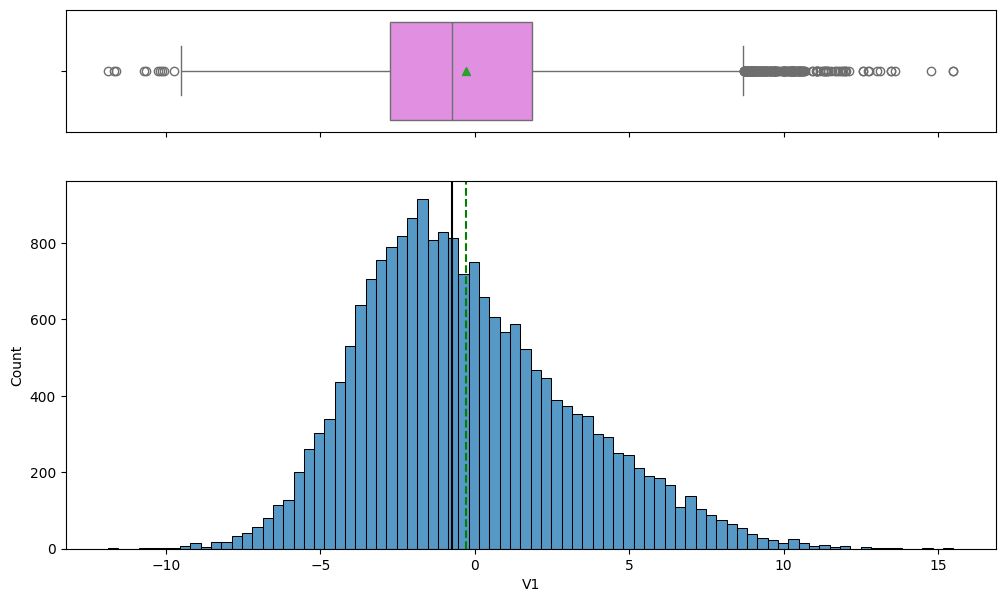

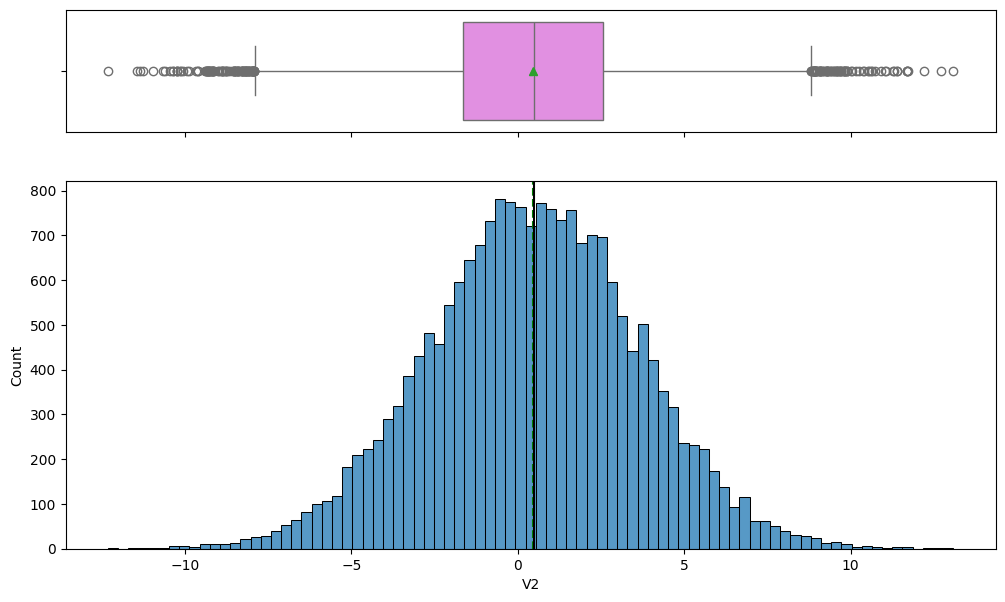

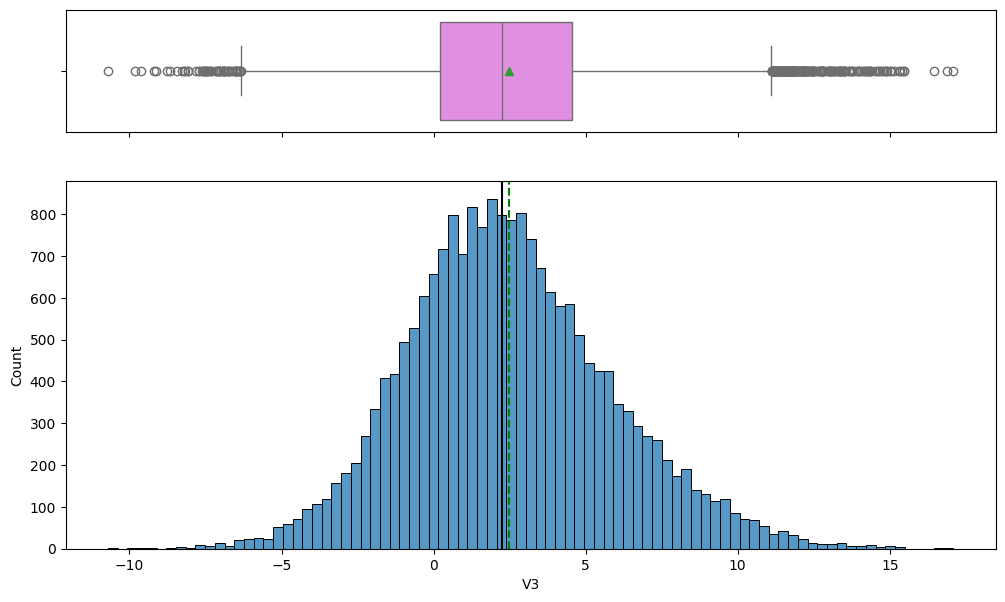

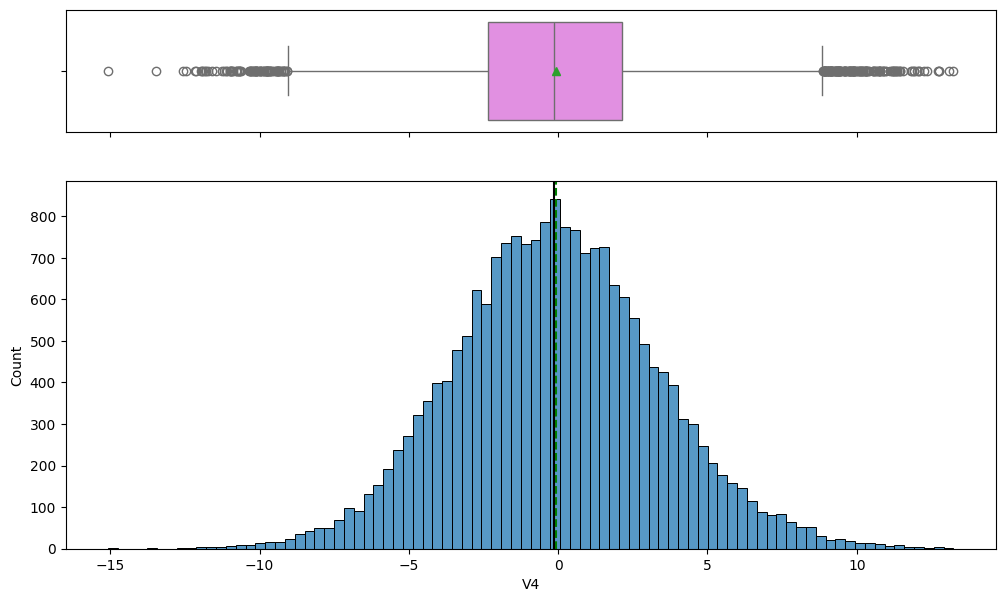

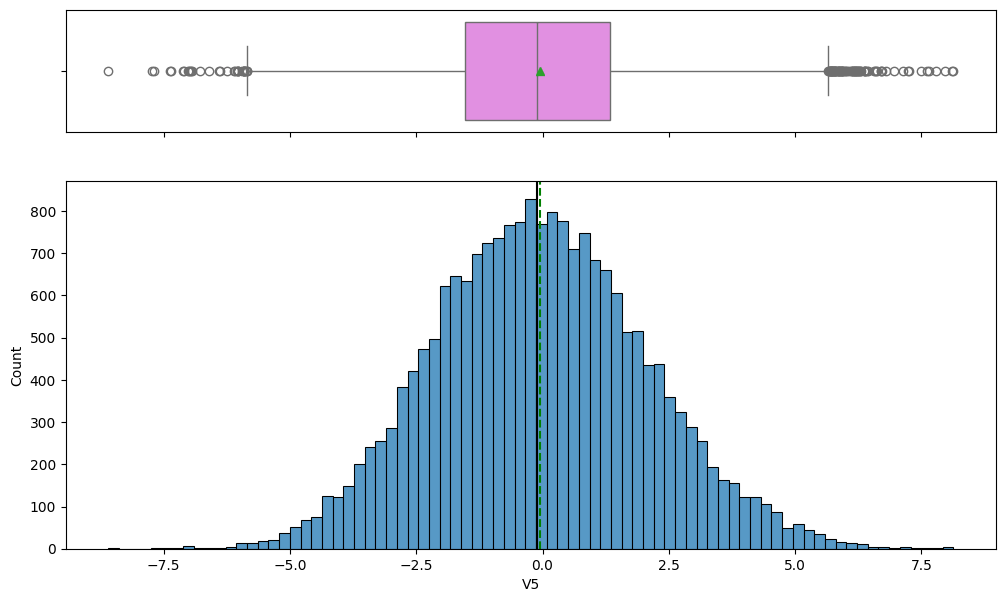

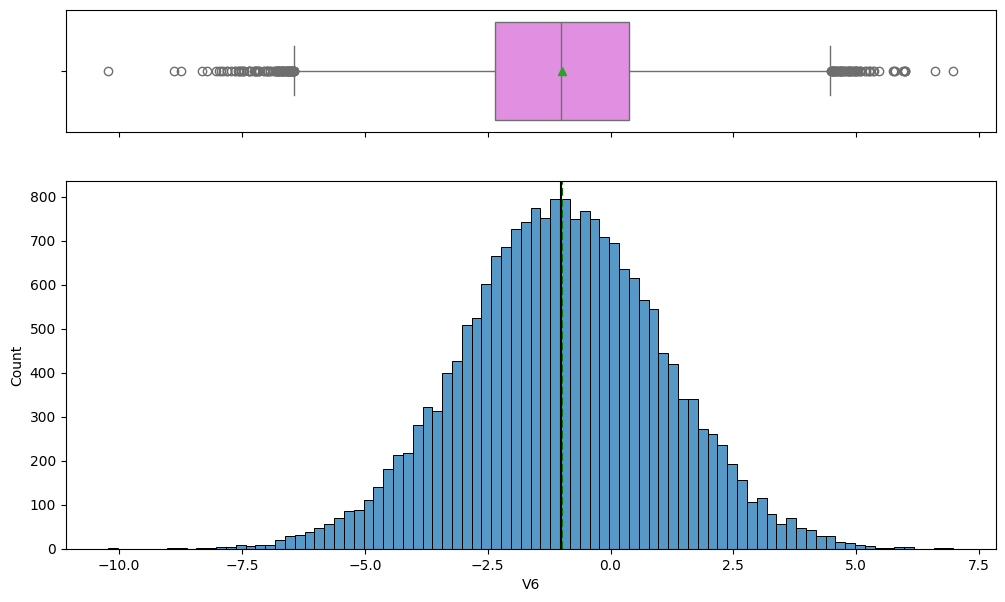

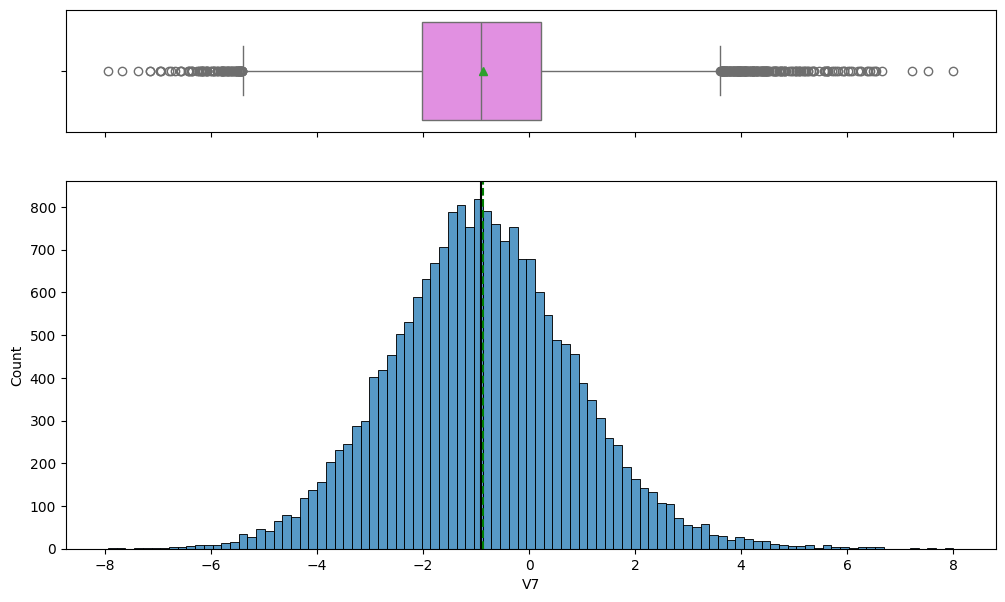

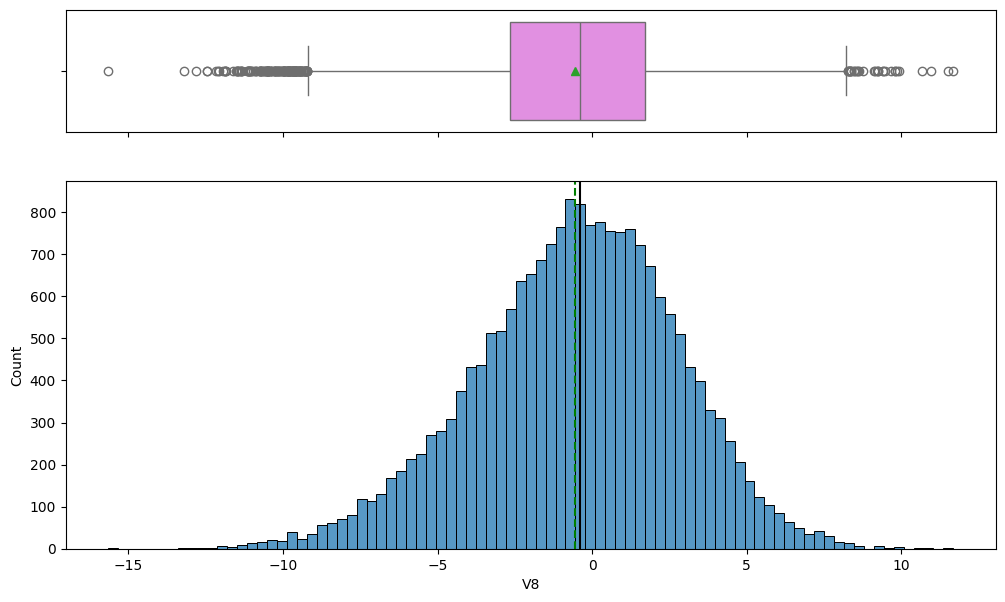

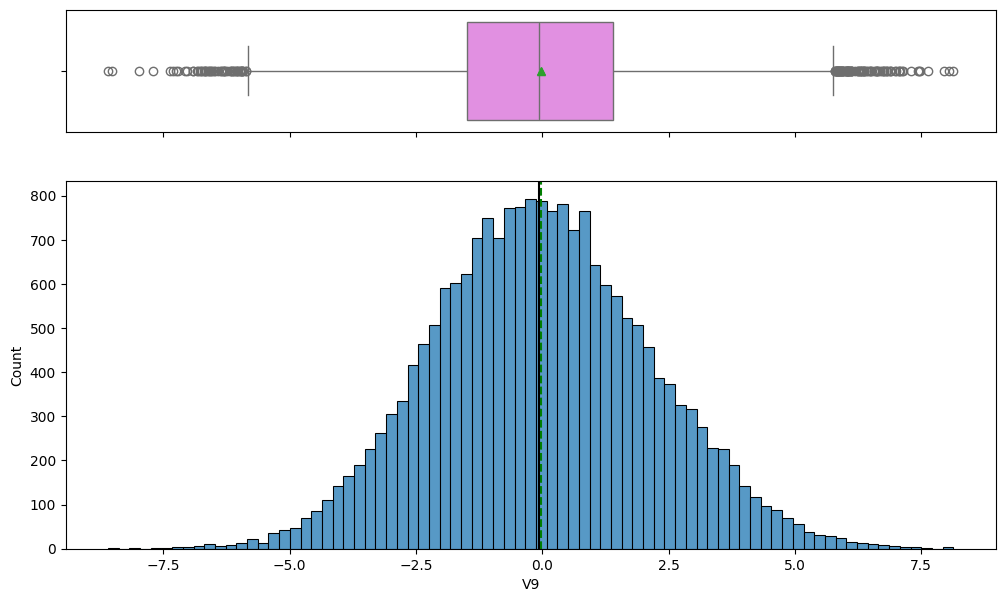

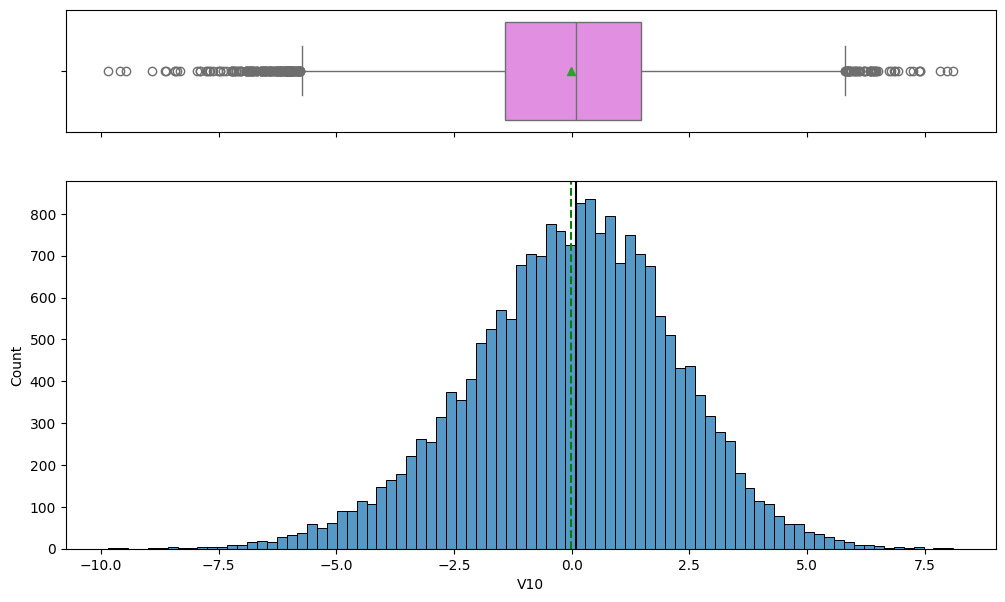

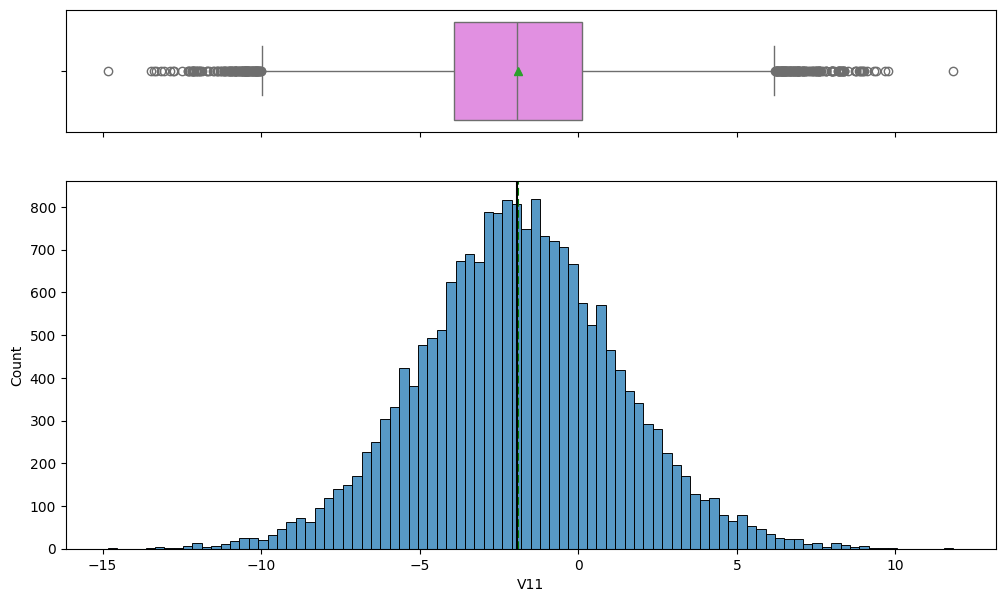

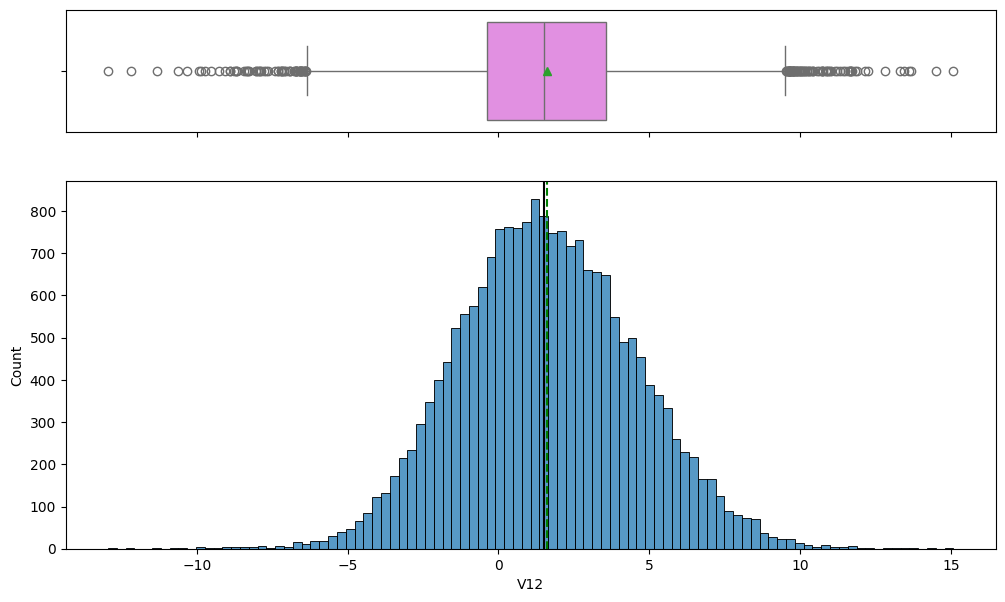

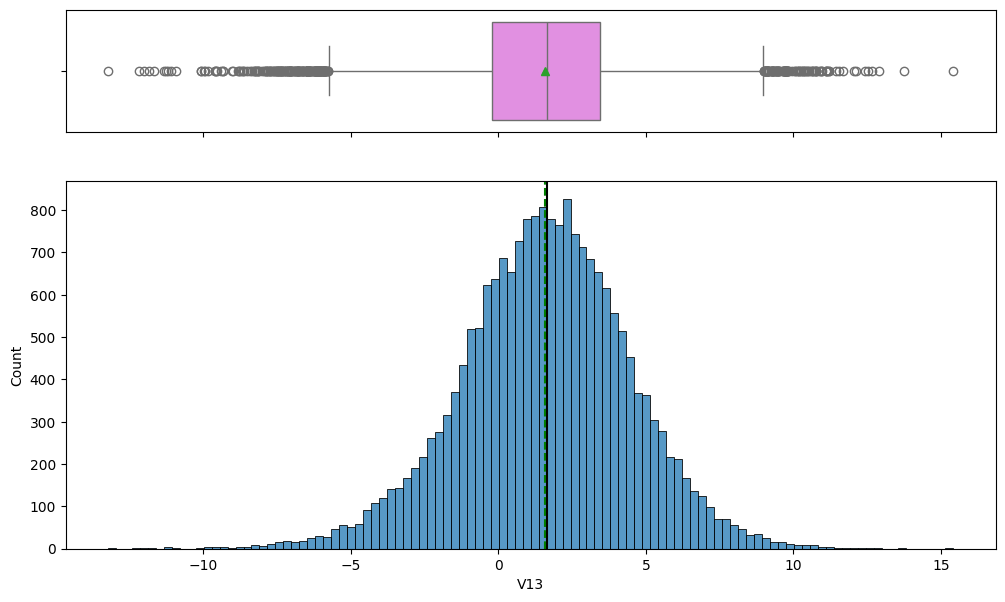

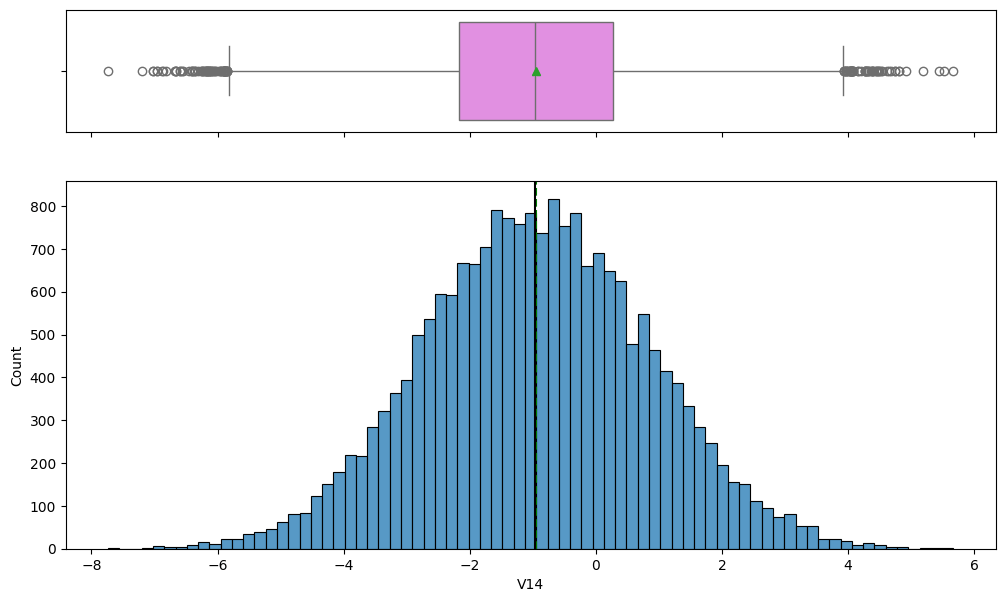

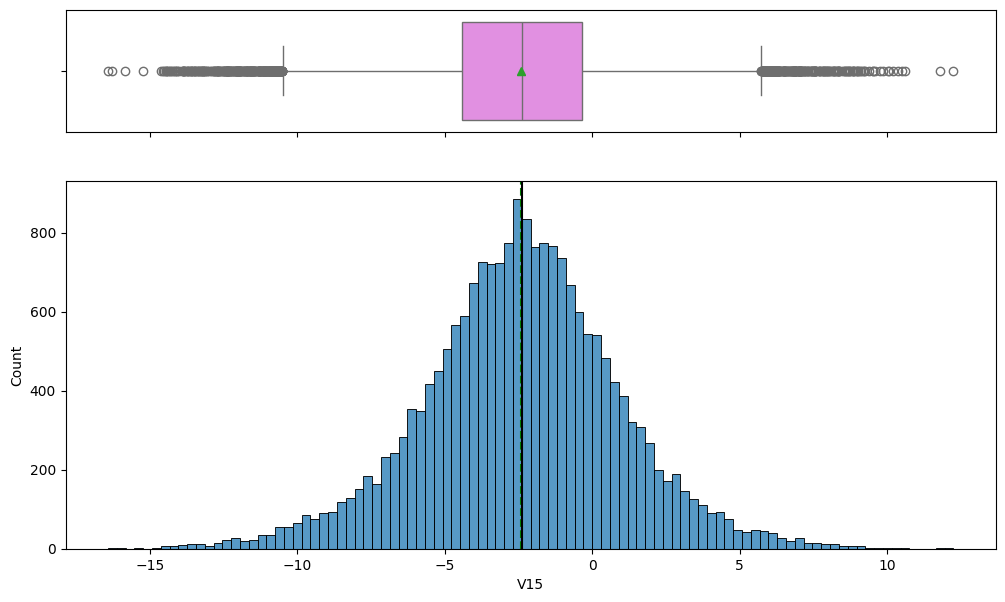

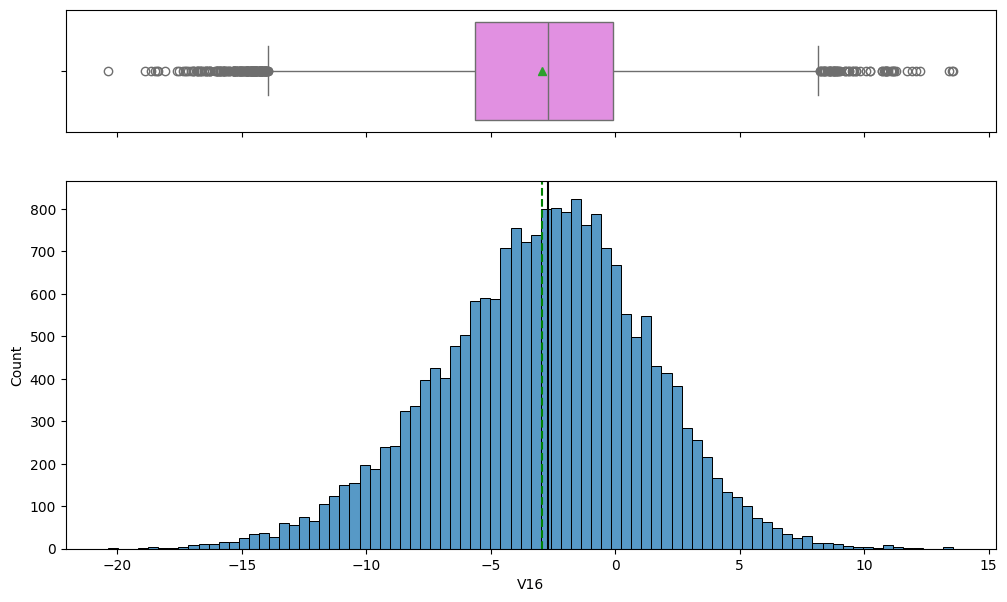

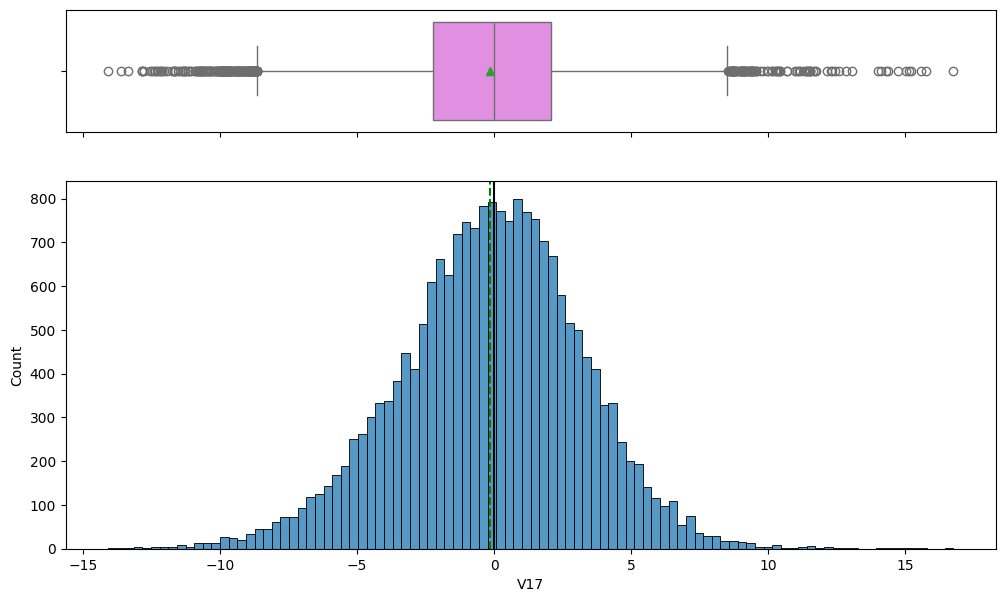

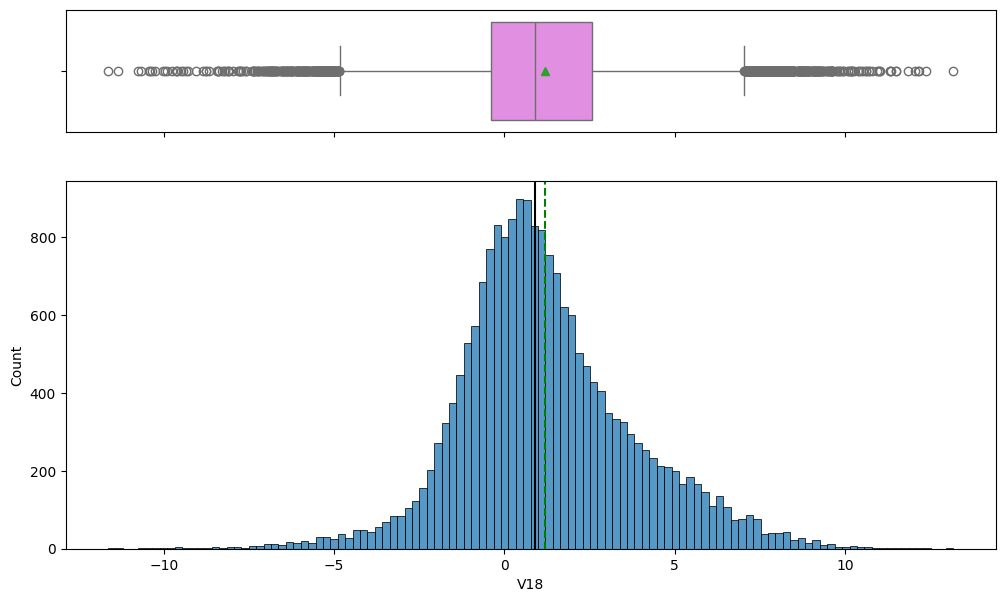

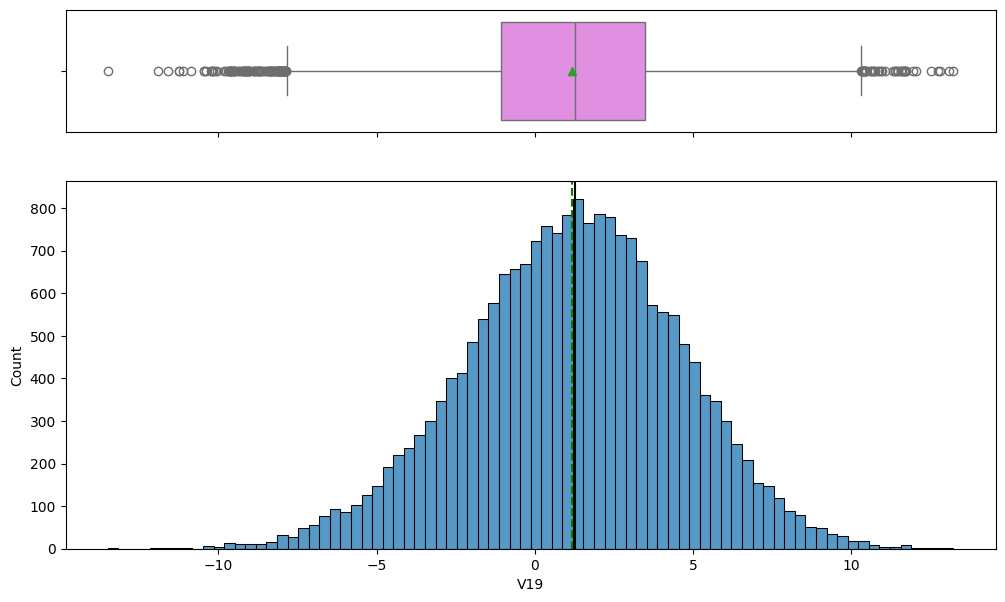

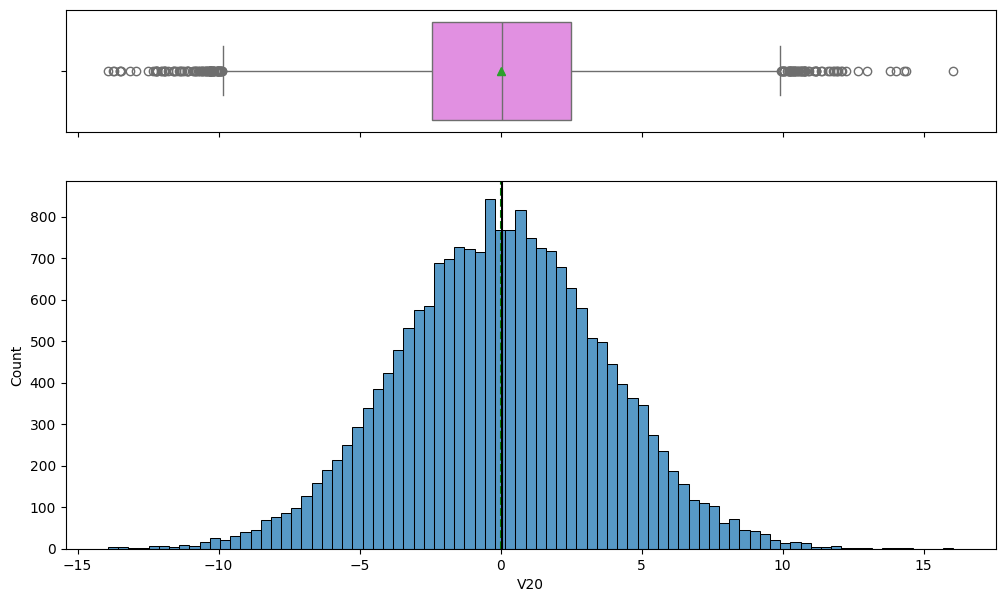

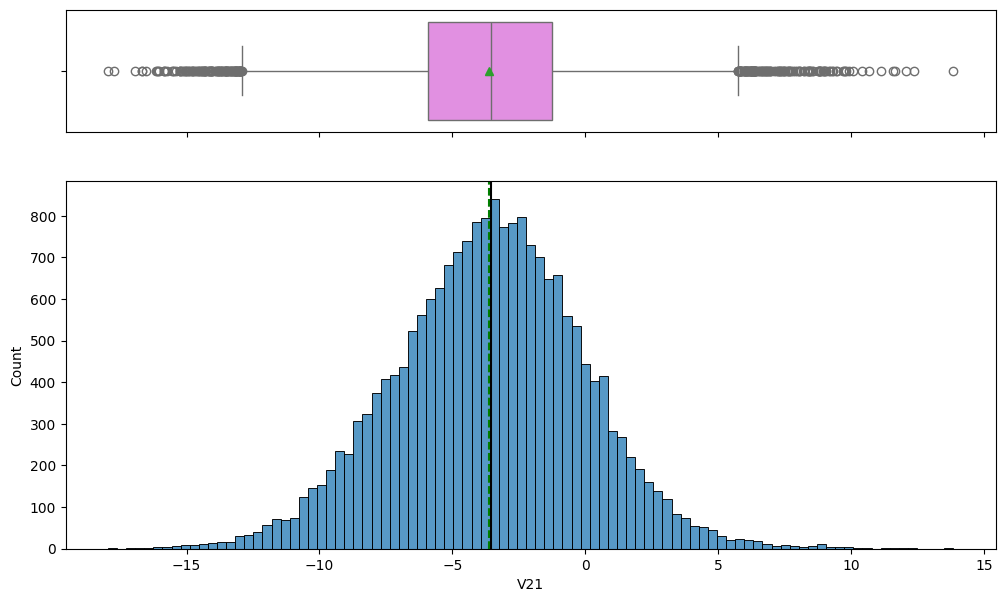

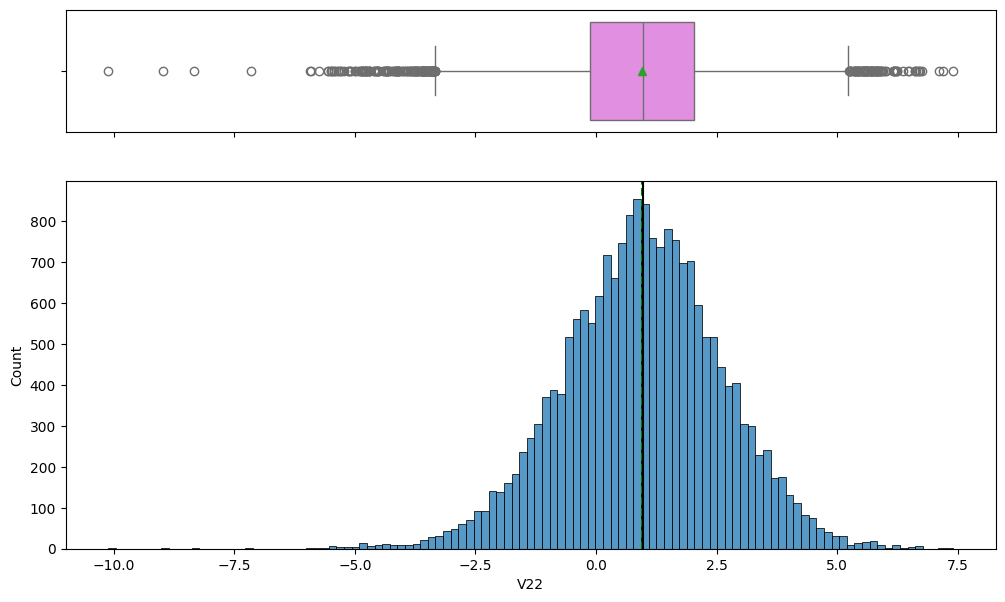

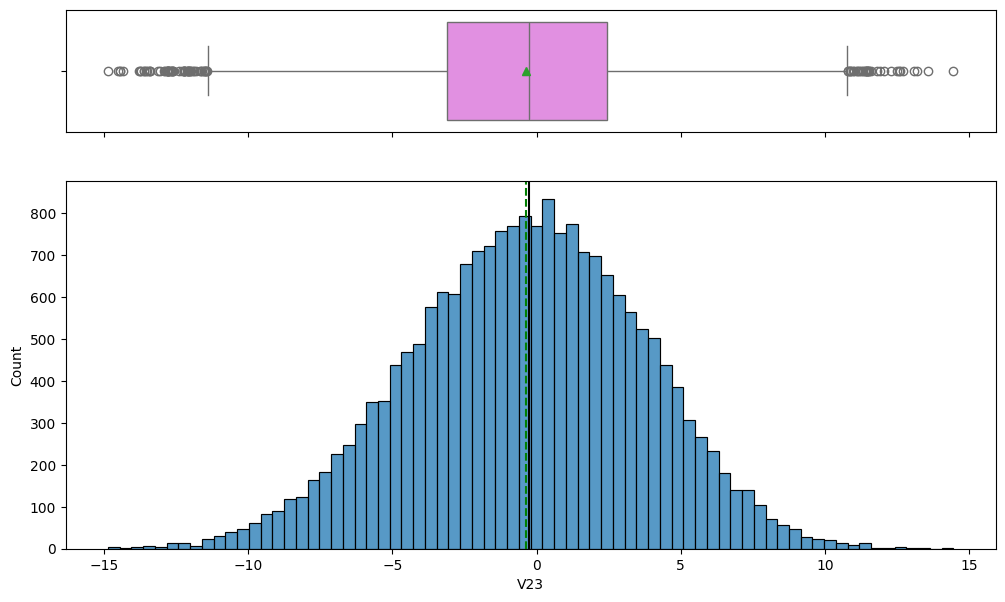

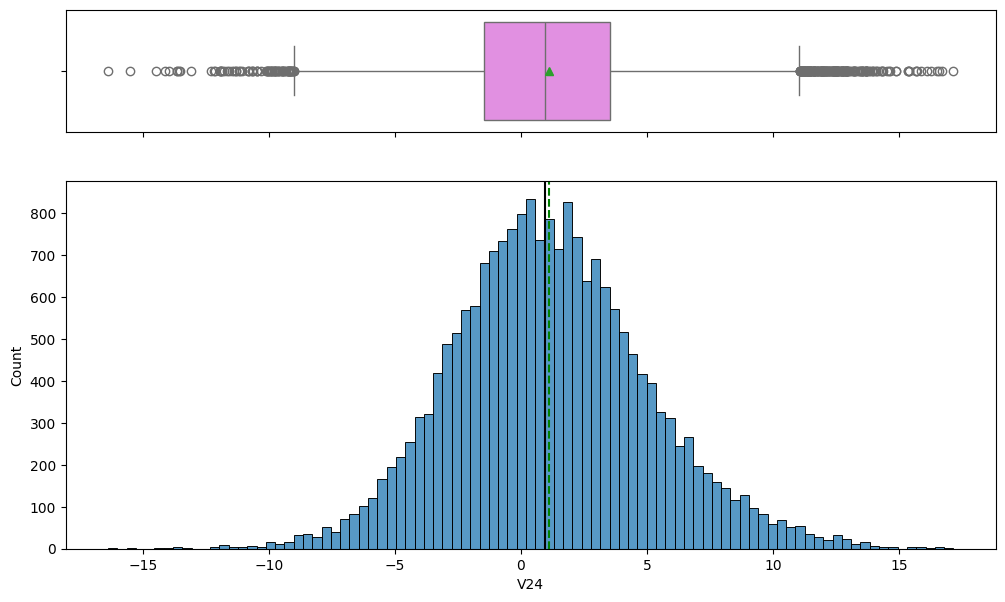

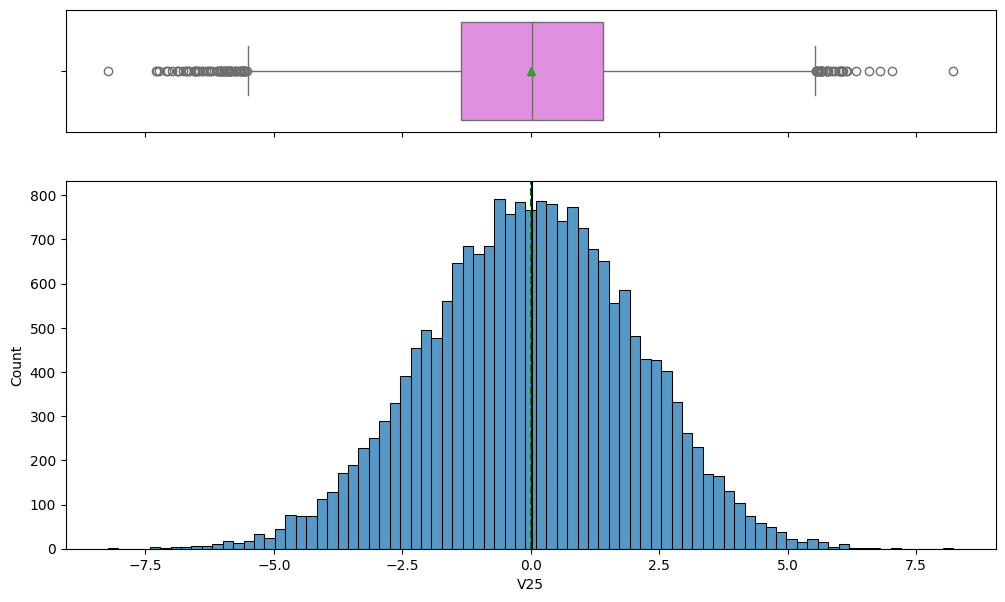

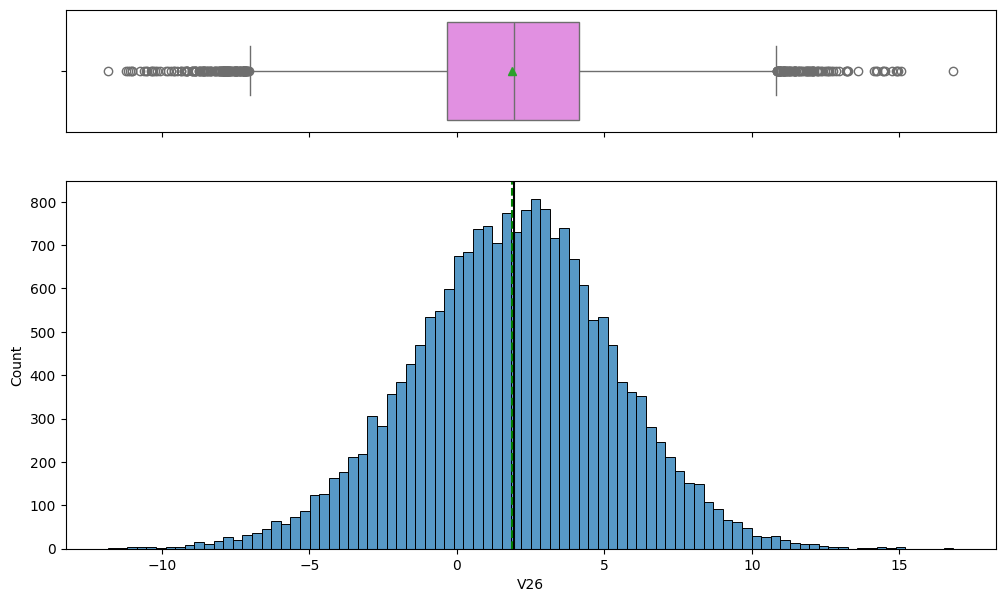

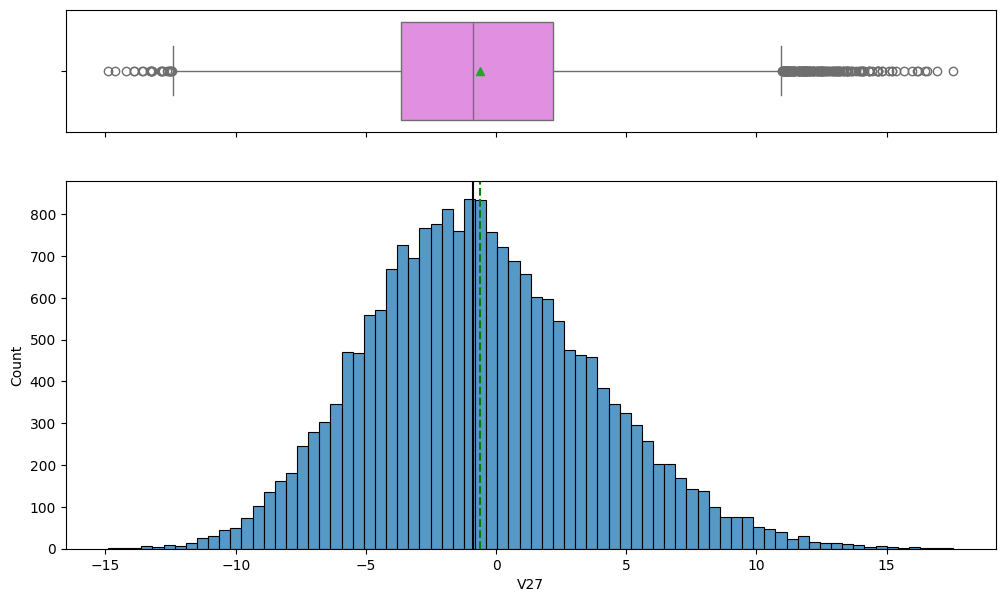

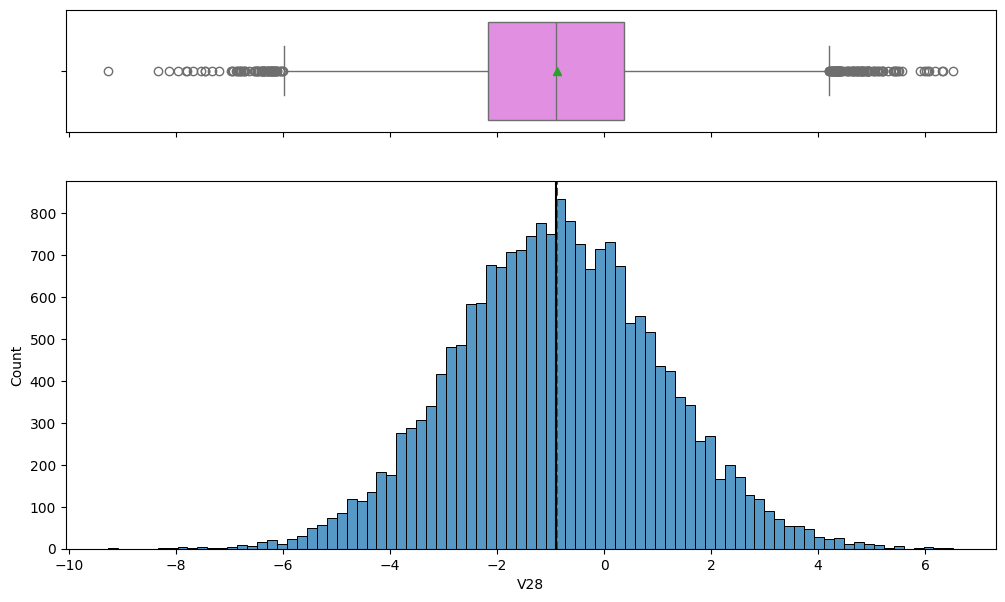

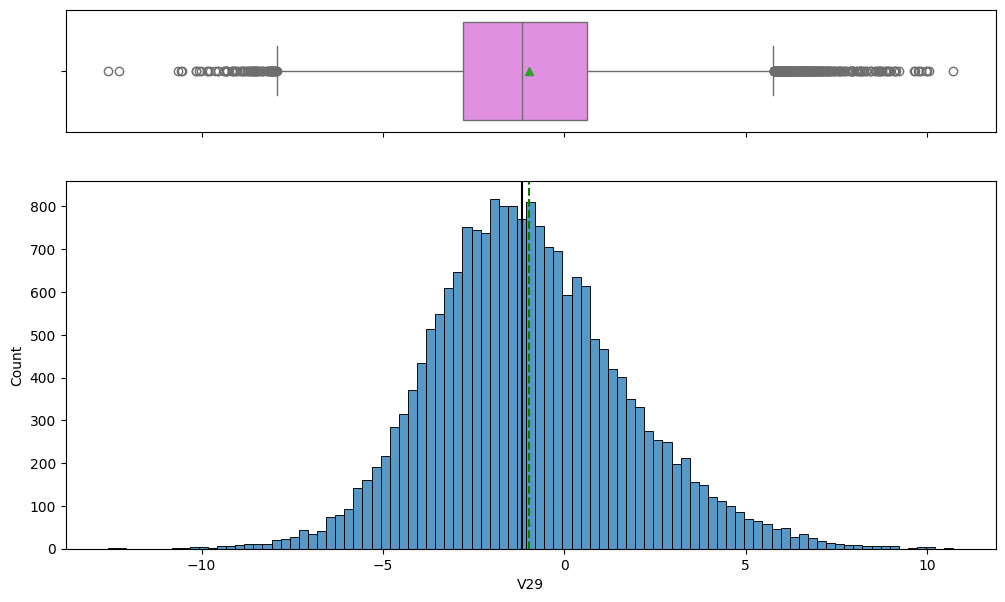

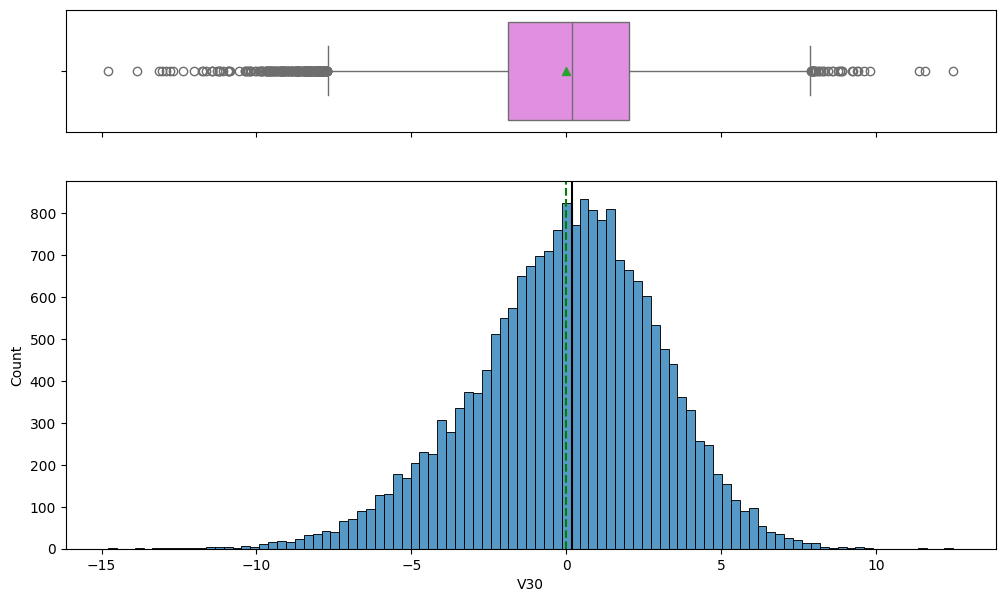

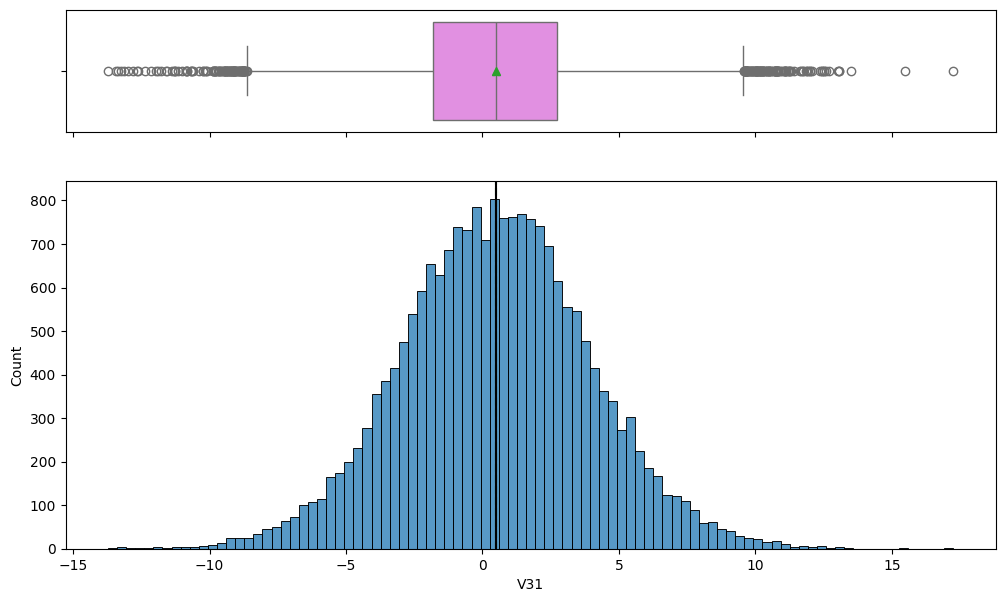

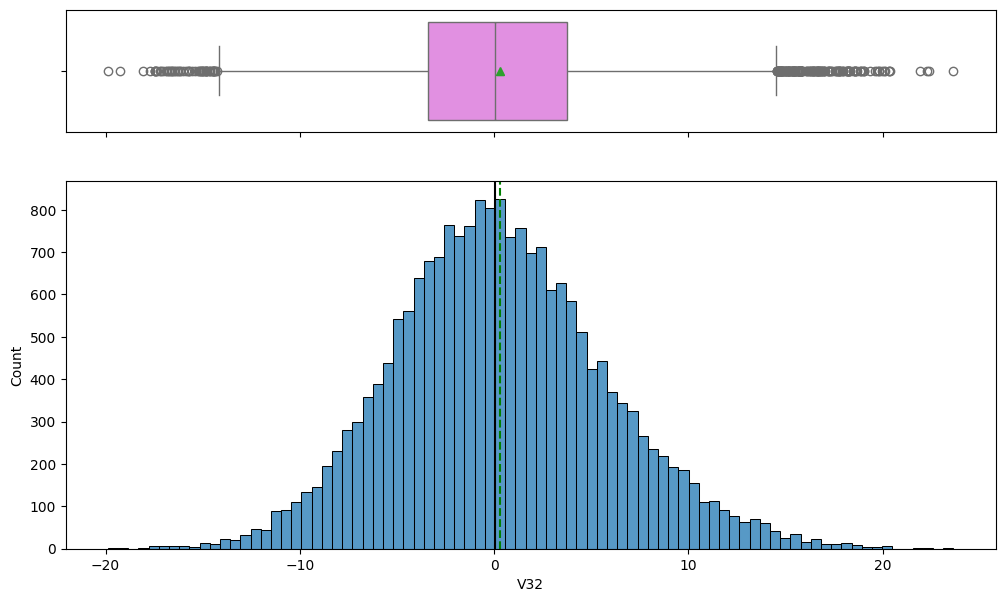

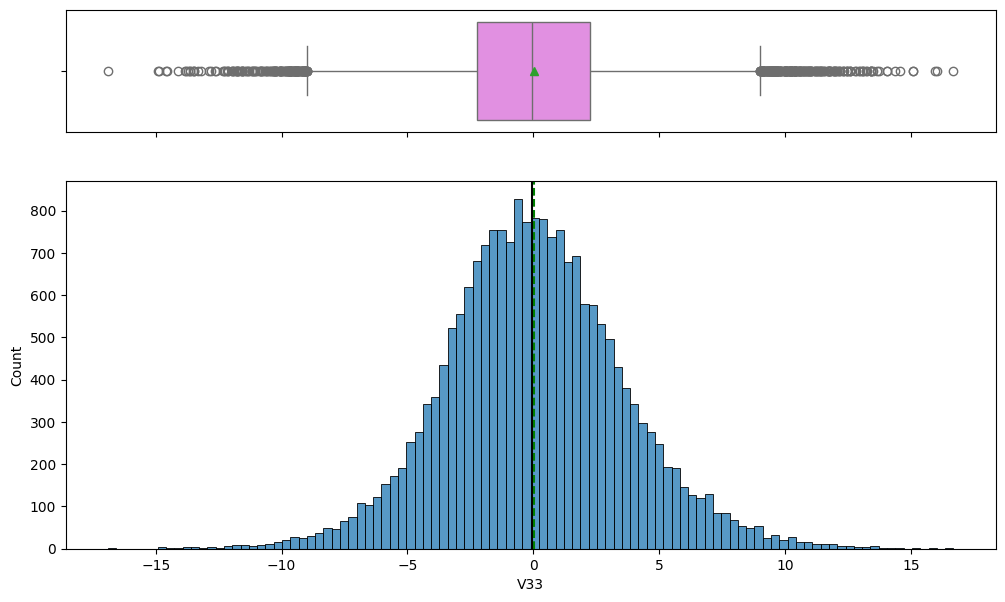

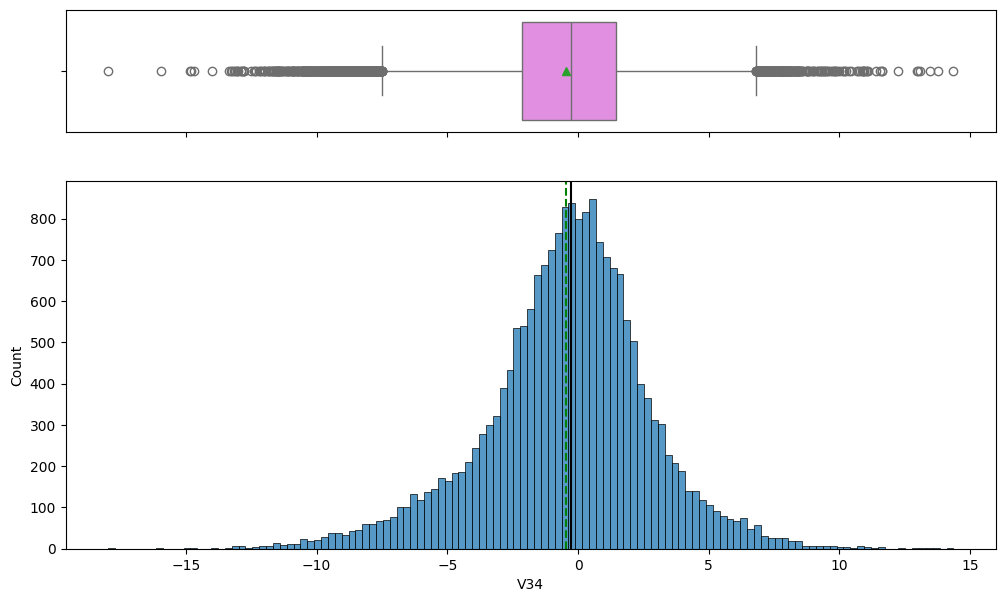

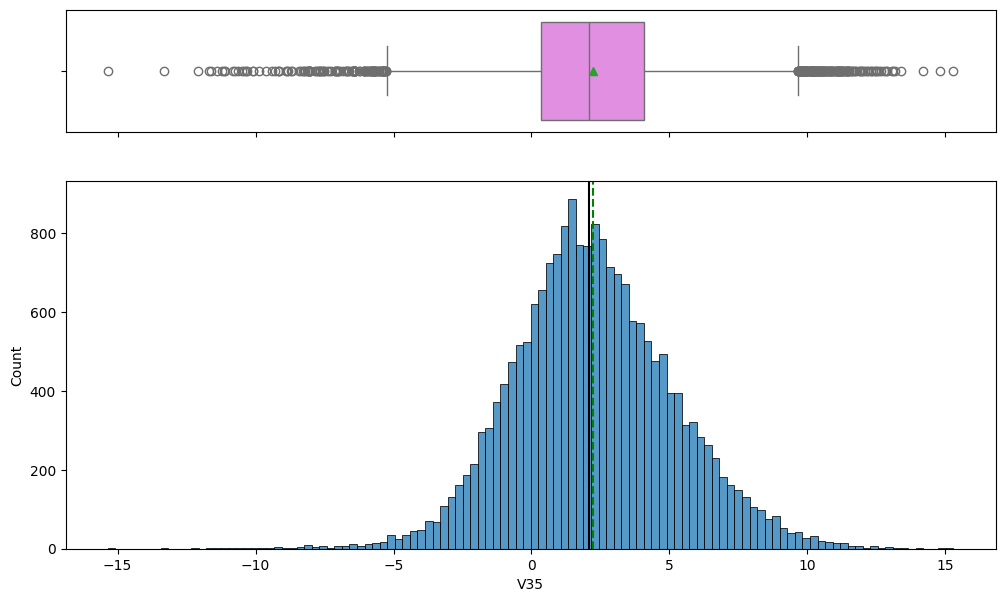

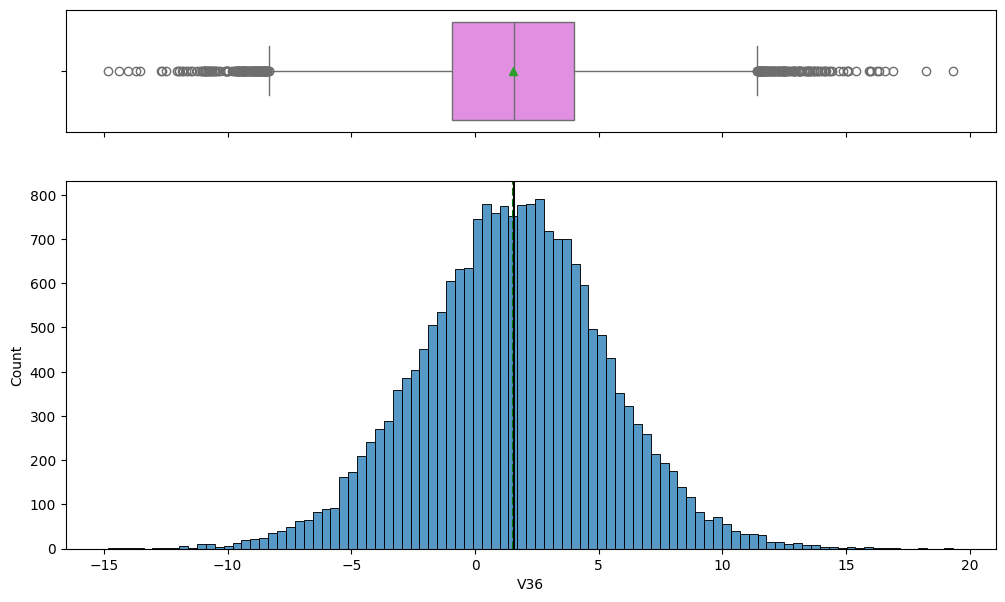

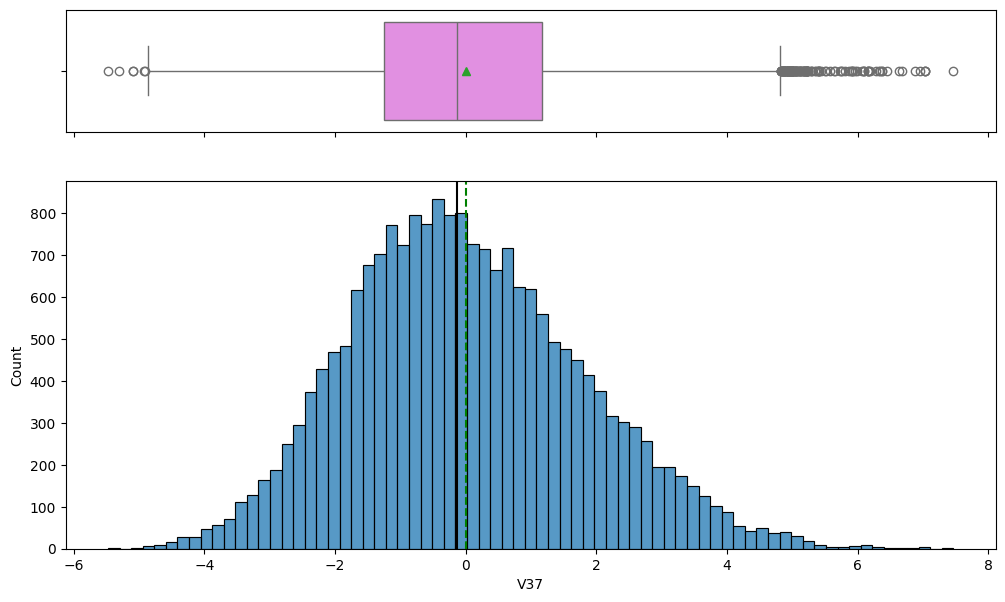

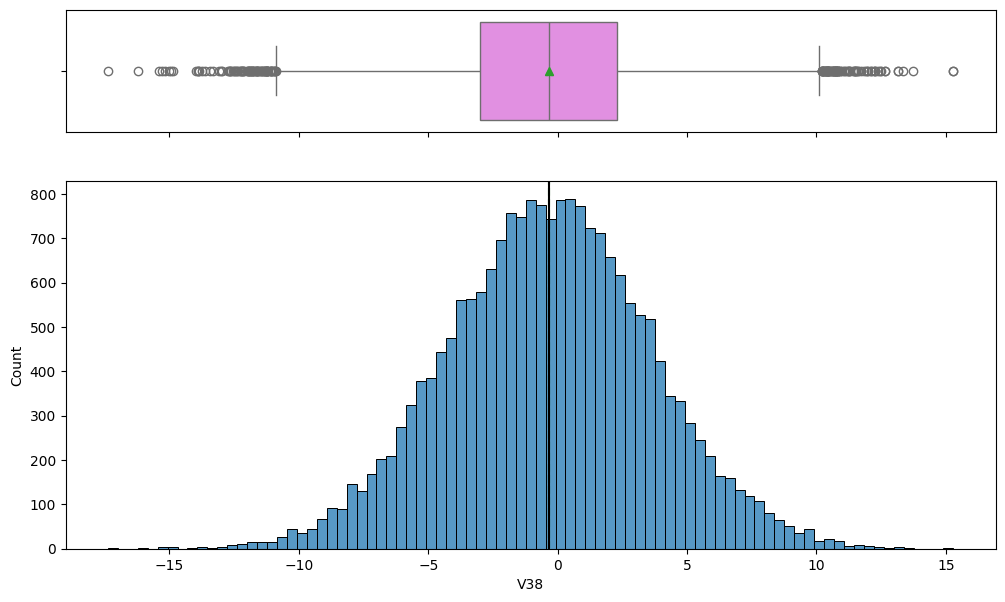

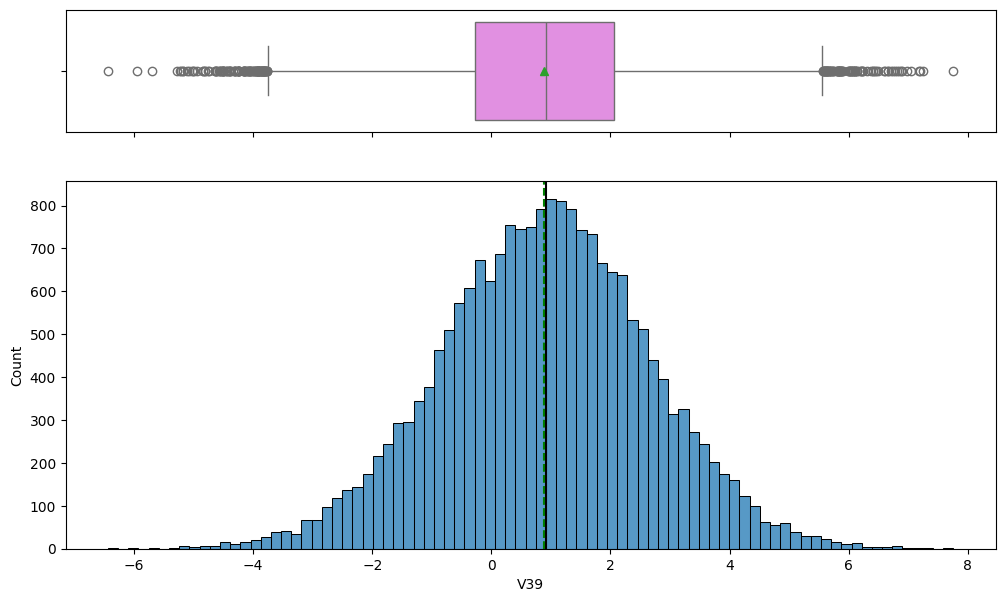

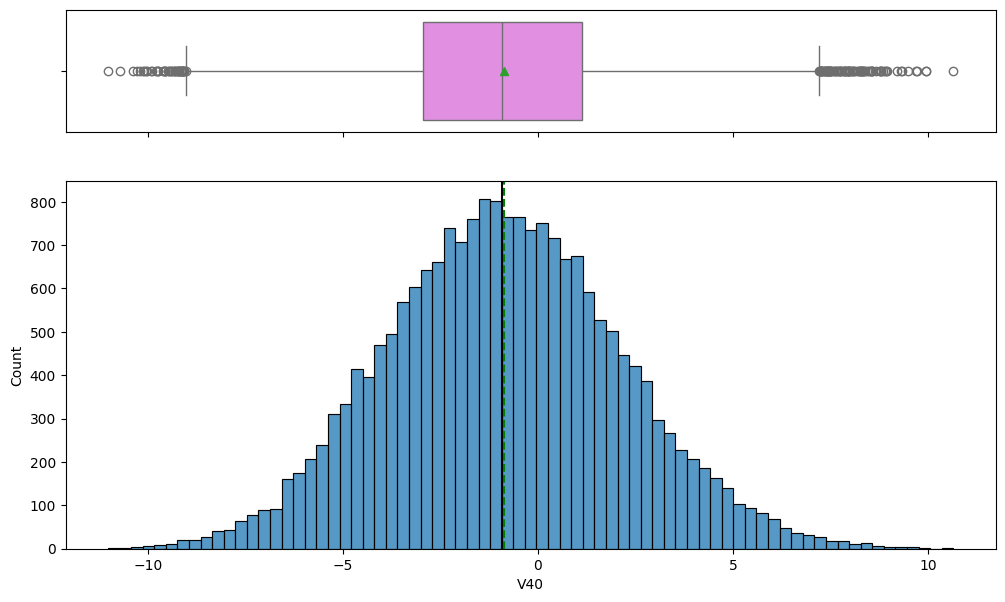

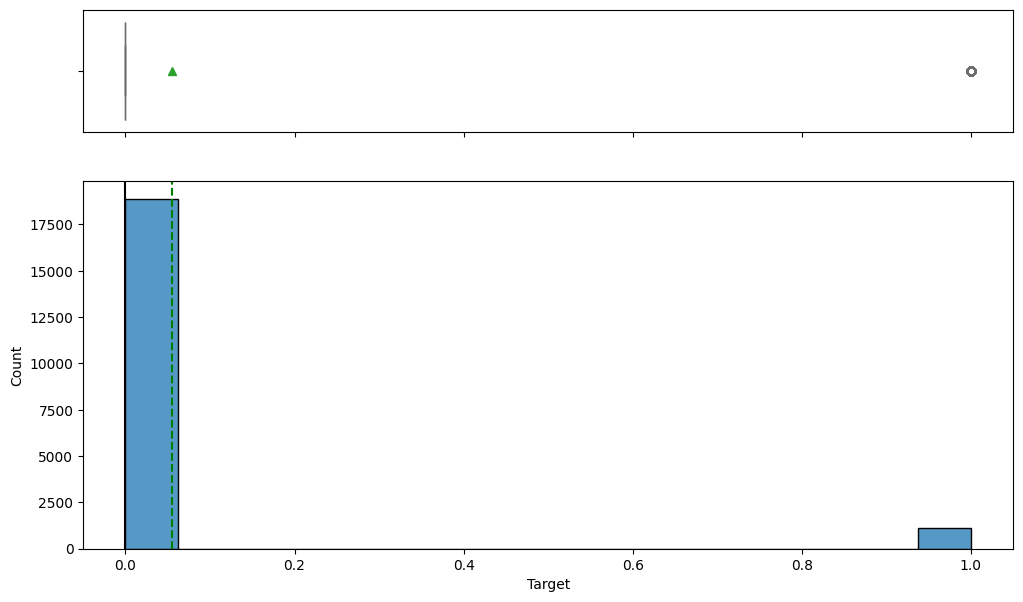

In [20]:
#Visualizing all the variables
for feature in data.columns:
    histogram_boxplot(df, feature, figsize=(12, 7), kde=False, bins=None)

- All of the Independenent variables seem to have a relatively normal distribution displaying a bell-shape like curve
- All the independent variables have outliers below the lower tail and above the upper tail.
  - We will consider these values to be true since there is no context behind the variables to say otherwise.
- The Depenented/Target variable has a imbalanced distribution with a vast majority being 0 (non-failiure)

###Target Variable Distribution for Train and Test sets

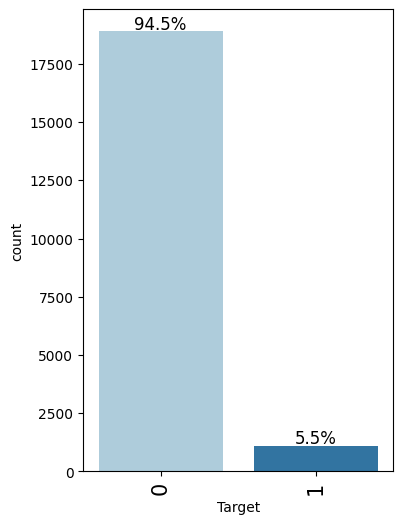

In [21]:
#visualize target variable in training data set
labeled_barplot(df, 'Target', perc=True)

In [22]:
data['Target'].value_counts(normalize= True)

Target
0   0.945
1   0.056
Name: proportion, dtype: float64

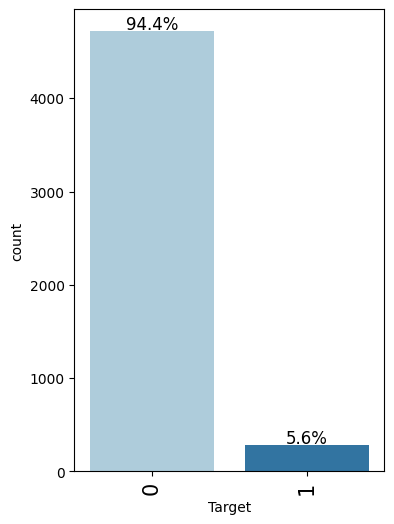

In [23]:
#visualize the target variable in the test data set
labeled_barplot(df_test, 'Target', perc=True)

In [24]:
data_test['Target'].value_counts(normalize=True)

Target
0   0.944
1   0.056
Name: proportion, dtype: float64

- The class distributions of the target variable in both the Train and Test data sets are nearly equal
  - Train Data Set: 94.5% being 0 (no failure) and 5.5% being 1 (failure)
  - Test Data Set: 94.4% being 0 (no failure) and 5.6% being 1 (failure)

###Bivariate Analysis - Correlation Heat Map

In [91]:
#Create a list of the all the variables
cols_list = data.select_dtypes(include=np.number).columns.tolist()

cols_list



['V1',
 'V2',
 'V3',
 'V4',
 'V5',
 'V6',
 'V7',
 'V8',
 'V9',
 'V10',
 'V11',
 'V12',
 'V13',
 'V14',
 'V15',
 'V16',
 'V17',
 'V18',
 'V19',
 'V20',
 'V21',
 'V22',
 'V23',
 'V24',
 'V25',
 'V26',
 'V27',
 'V28',
 'V29',
 'V30',
 'V31',
 'V32',
 'V33',
 'V34',
 'V35',
 'V36',
 'V37',
 'V38',
 'V39',
 'V40',
 'Target']

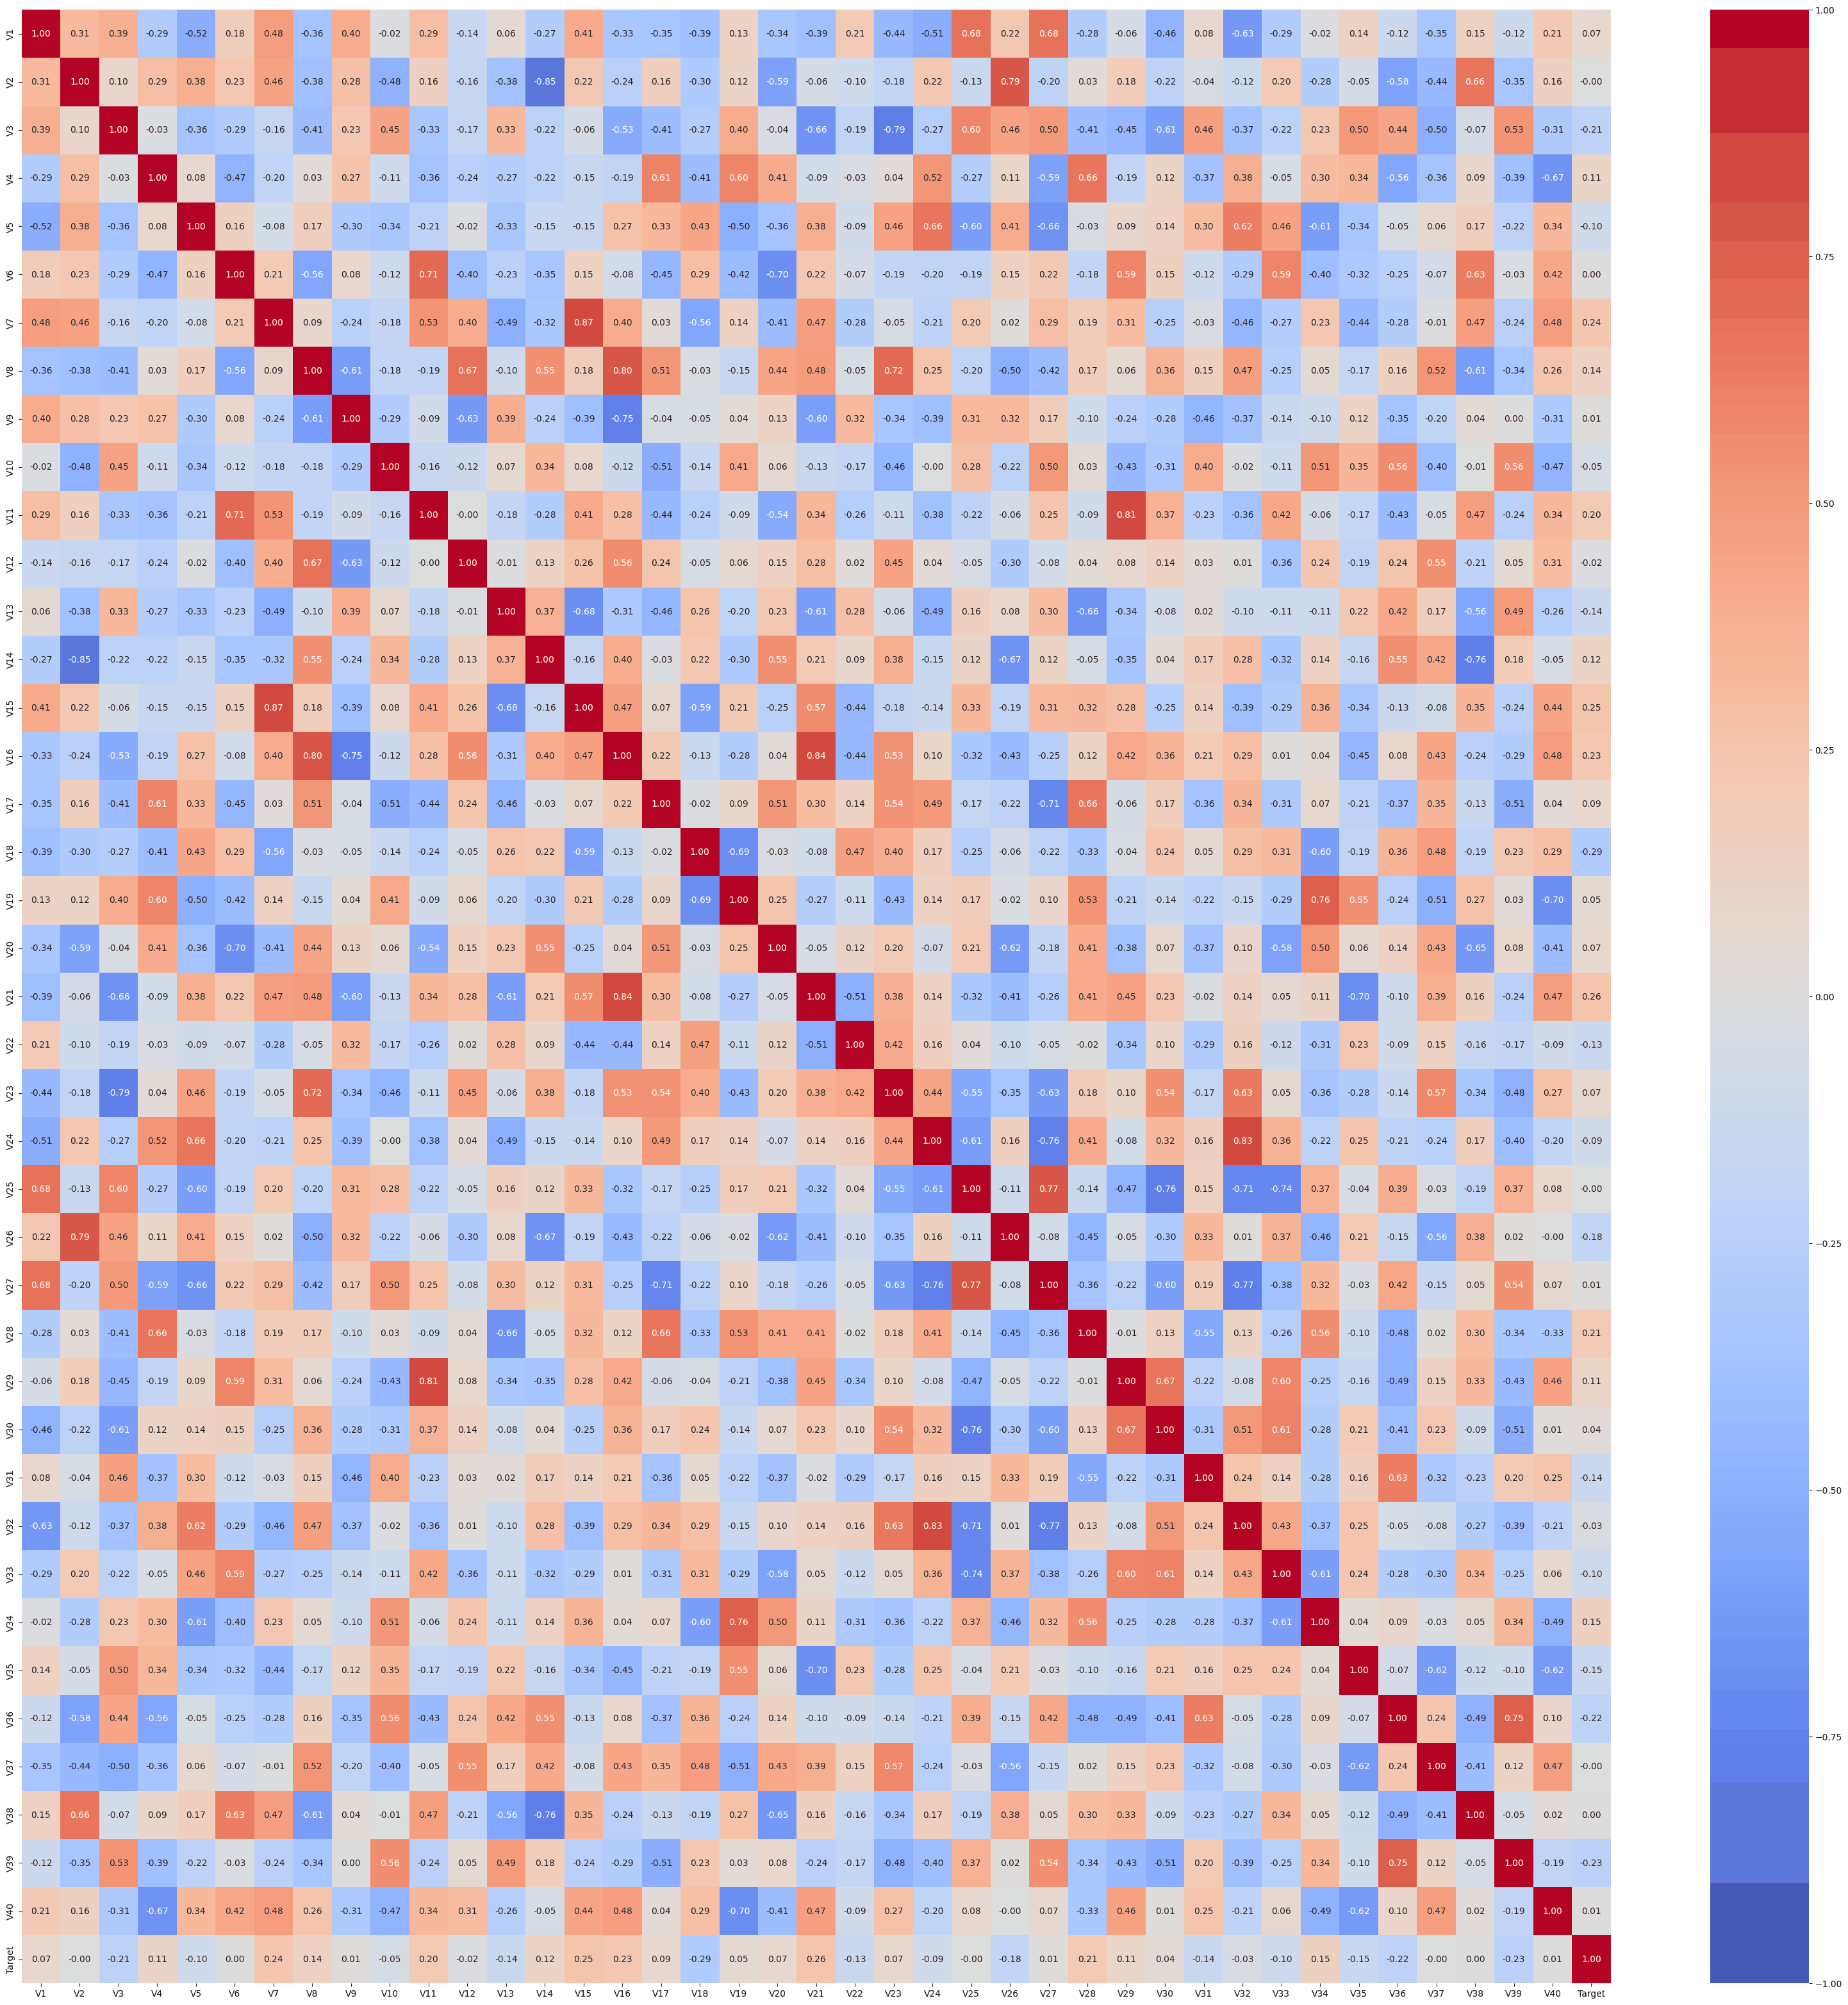

In [92]:
#Visualize heat map of numerical values
plt.figure(figsize=(40,40))
sns.heatmap(data[cols_list].corr(), annot=True, vmin= -1, vmax= 1, fmt='.2f',  cmap='coolwarm')
plt.show()

## Data Pre-processing

In [25]:
#Splitting the Train Data set into X and y
X= data.drop(['Target'], axis=1)
y= data['Target']

- The Test is already separated from the training set so we don't have to perform this split, however, we will be splitting the train data set into Train and Validation sets.

In [26]:
#Splitting the data into train and validation sets

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.25, random_state=1 ,stratify= y
)

In [27]:
#check the number of rows and columns in both train and validation sets

print('X_train shape:', X_train.shape, 'and X_val shape:', X_val.shape)

X_train shape: (15000, 40) and X_val shape: (5000, 40)


In [31]:
#Check the distribution of the target variable held through the train/validation split
print('y_train target variable distribution', y_train.value_counts(normalize=True))

print('y_val target variable distribution', y_val.value_counts(normalize=True))

y_train target variable distribution Target
0   0.945
1   0.055
Name: proportion, dtype: float64
y_val target variable distribution Target
0   0.944
1   0.056
Name: proportion, dtype: float64


In [28]:
#Split the test data into X_test and y_test
X_test= data_test.drop(['Target'], axis=1)
y_test= data_test['Target']

In [29]:
#Checking the number of rows and columns in X_test
print('X_test shape:', X_test.shape)

X_test shape: (5000, 40)


- The data has been split into 3 groups
  - X_train has 15,000 rows with 40 columns
  - X_val has 5,000 rows with 40 columns
  - X_test has 5,000 rows with 40 columns

## Missing Value Imputation




- Since there is limited context behind the variables and only a small portion of the data is missing values, we will impute with the median values using a SimpleImputer

In [32]:
# create a function for imputation with the median to be used in transforming and fitting
imputer = SimpleImputer(strategy='median')

In [33]:
#Fit and Transform Train data
X_train= pd.DataFrame(imputer.fit_transform(X_train), columns = X_train.columns)

#Transform the Validation Data
X_val= pd.DataFrame(imputer.transform(X_val), columns = X_val.columns)

#Transform the Test Data
X_test= pd.DataFrame(imputer.transform(X_test), columns = X_test.columns)

In [34]:
#Checking that all missing values have been treated in all 3 data sets
print(X_train.isna().sum())
print('-'*30)
print(X_val.isna().sum())
print('-'*30)
print(X_test.isna().sum())
print('-'*30)

V1     0
V2     0
V3     0
V4     0
V5     0
V6     0
V7     0
V8     0
V9     0
V10    0
V11    0
V12    0
V13    0
V14    0
V15    0
V16    0
V17    0
V18    0
V19    0
V20    0
V21    0
V22    0
V23    0
V24    0
V25    0
V26    0
V27    0
V28    0
V29    0
V30    0
V31    0
V32    0
V33    0
V34    0
V35    0
V36    0
V37    0
V38    0
V39    0
V40    0
dtype: int64
------------------------------
V1     0
V2     0
V3     0
V4     0
V5     0
V6     0
V7     0
V8     0
V9     0
V10    0
V11    0
V12    0
V13    0
V14    0
V15    0
V16    0
V17    0
V18    0
V19    0
V20    0
V21    0
V22    0
V23    0
V24    0
V25    0
V26    0
V27    0
V28    0
V29    0
V30    0
V31    0
V32    0
V33    0
V34    0
V35    0
V36    0
V37    0
V38    0
V39    0
V40    0
dtype: int64
------------------------------
V1     0
V2     0
V3     0
V4     0
V5     0
V6     0
V7     0
V8     0
V9     0
V10    0
V11    0
V12    0
V13    0
V14    0
V15    0
V16    0
V17    0
V18    0
V19    0
V20    0
V21    0
V22

- All missing values have been treated in all 3 data sets. There are no more missing values.

## Model Building

### Model evaluation criterion

The nature of predictions made by the classification model will translate as follows:

- True positives (TP) are failures correctly predicted by the model.
- True negatives (TN) are non failures correctly predicted by the model.
- False negatives (FN) are real failures in a generator where there is no detection by model.
- False positives (FP) are failure detections in a generator where there is no failure.


**Which metric to optimize?**

* We need to choose the metric which will ensure that the maximum number of generator failures are predicted correctly by the model.
* We would want Recall to be maximized as greater the Recall, the higher the chances of minimizing false negatives.
* We want to minimize false negatives because if a model predicts that a machine will have no failure when there will be a failure, it will increase the maintenance cost.

**Let's define a function to output different metrics (including recall) on the train and test set and a function to show confusion matrix so that we do not have to use the same code repetitively while evaluating models.**

In [35]:
# defining a function to compute different metrics to check performance of a classification model built using sklearn
def model_performance_classification_sklearn(model, predictors, target):
    """
    Function to compute different metrics to check classification model performance

    model: classifier
    predictors: independent variables
    target: dependent variable
    """

    # predicting using the independent variables
    pred = model.predict(predictors)

    acc = accuracy_score(target, pred)  # to compute Accuracy
    recall = recall_score(target, pred)  # to compute Recall
    precision = precision_score(target, pred)  # to compute Precision
    f1 = f1_score(target, pred)  # to compute F1-score

    # creating a dataframe of metrics
    df_perf = pd.DataFrame(
        {
            "Accuracy": acc,
            "Recall": recall,
            "Precision": precision,
            "F1": f1

        },
        index=[0],
    )

    return df_perf

In [36]:
def confusion_matrix_sklearn(model, predictors, target):
    """
    To plot the confusion_matrix with percentages

    model: classifier
    predictors: independent variables
    target: dependent variable
    """
    y_pred = model.predict(predictors)
    cm = confusion_matrix(target, y_pred)
    labels = np.asarray(
        [
            ["{0:0.0f}".format(item) + "\n{0:.2%}".format(item / cm.flatten().sum())]
            for item in cm.flatten()
        ]
    ).reshape(2, 2)

    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=labels, fmt="")
    plt.ylabel("True label")
    plt.xlabel("Predicted label")

### Defining scorer to be used for cross-validation and hyperparameter tuning

- We want to reduce false negatives and will try to maximize "Recall".
- To maximize Recall, we can use Recall as a **scorer** in cross-validation and hyperparameter tuning.

In [37]:
# Type of scoring used to compare parameter combinations
scorer = metrics.make_scorer(metrics.recall_score)

**Since we have completed pre-processing the data and definined the evaluation criterion, we can now move on to building the models.**

### Model Building with original data

In [38]:
%%time

models = []  # Empty list to store all the models

# Appending models into the list
models.append(("dtree", DecisionTreeClassifier(random_state=1)))
models.append(("Logistic Regression", LogisticRegression(random_state=1)))
models.append(("Random Forest", RandomForestClassifier(random_state=1)))
models.append(("Bagging", BaggingClassifier(random_state=1)))
models.append(("AdaBoost", AdaBoostClassifier(random_state=1)))
models.append(("GBM", GradientBoostingClassifier(random_state=1)))
models.append(("XGBoost", XGBClassifier(random_state=1, eval_metric='logloss')))


results1 = []  # Empty list to store all model's CV scores
names = []  # Empty list to store name of the models


# loop through all models to get the mean cross validated score
print("\n" "Cross-Validation performance on training dataset:" "\n")

for name, model in models:
    kfold = StratifiedKFold(
        n_splits=5, shuffle=True, random_state=1
    )  # Setting number of splits equal to 5
    cv_result = cross_val_score(
        estimator=model, X=X_train, y=y_train, scoring=scorer, cv=kfold
    )
    results1.append(cv_result)
    names.append(name)
    print("{}: {}".format(name, cv_result.mean()))

print("\n" "Validation Performance:" "\n")

for name, model in models:
    model.fit(X_train, y_train)
    scores = recall_score(y_val, model.predict(X_val))
    print("{}: {}".format(name, scores))


Cross-Validation performance on training dataset:

dtree: 0.6982829521679532
Logistic Regression: 0.4927566553639709
Random Forest: 0.7235192266070268
Bagging: 0.7210807301060529
AdaBoost: 0.6309140754635308
GBM: 0.7066661857008874
XGBoost: 0.8100497799581561

Validation Performance:

dtree: 0.7050359712230215
Logistic Regression: 0.48201438848920863
Random Forest: 0.7266187050359713
Bagging: 0.7302158273381295
AdaBoost: 0.6762589928057554
GBM: 0.7230215827338129
XGBoost: 0.8309352517985612
CPU times: user 5min 44s, sys: 1.07 s, total: 5min 45s
Wall time: 6min 2s


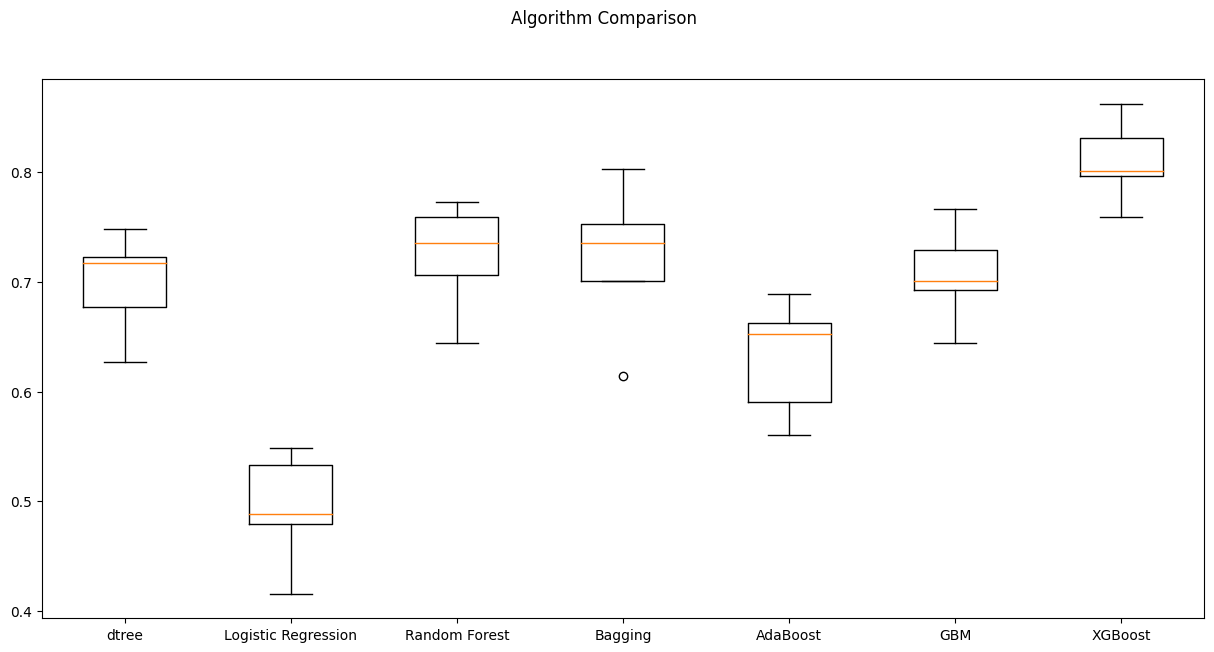

In [39]:
#Visualize CV scores of all models defined above using a boxplot
fig = plt.figure(figsize= (15,7))

fig.suptitle('Algorithm Comparison')
ax= fig.add_subplot(111)

plt.boxplot(results1)
ax.set_xticklabels(names)

plt.show()

With models built on the original data:
- We can see that XGBoost is giving the highest cross-validated recall followed by Random Forest and Bagging
- These models are also generalizing decently well on the validation data set with comparable performance


### Model Building with Oversampled data


In [40]:
# Synthetic Minority Over Sampling Technique
sm = SMOTE(sampling_strategy=1, k_neighbors=5, random_state=1)
X_train_over, y_train_over = sm.fit_resample(X_train, y_train)



In [41]:
print("Before Oversampling, counts of label '1': {}".format(sum(y_train==1)))
print("Before Oversampling, counts of label '0': {} \n".format(sum(y_train==0)))

print("After Oversampling, counts of label '1': {}".format(sum(y_train_over==1)))
print("After Oversampling, counts of label '0': {} \n".format(sum(y_train_over==0)))

print("After Oversampling, the shape of X_train: {}".format(X_train_over.shape))
print("After Oversampling, the shape of y_train: {} \n".format(y_train_over.shape))

Before Oversampling, counts of label '1': 832
Before Oversampling, counts of label '0': 14168 

After Oversampling, counts of label '1': 14168
After Oversampling, counts of label '0': 14168 

After Oversampling, the shape of X_train: (28336, 40)
After Oversampling, the shape of y_train: (28336,) 



In [42]:
%%time

models = []  # Empty list to store all the models

# Appending models into the list
models.append(("dtree", DecisionTreeClassifier(random_state=1)))
models.append(("Logistic Regression", LogisticRegression(random_state=1)))
models.append(("Random Forest", RandomForestClassifier(random_state=1)))
models.append(("Bagging", BaggingClassifier(random_state=1)))
models.append(("AdaBoost", AdaBoostClassifier(random_state=1)))
models.append(("GBM", GradientBoostingClassifier(random_state=1)))
models.append(("XGBoost", XGBClassifier(random_state=1, eval_metric='logloss')))


results1 = []  # Empty list to store all model's CV scores
names = []  # Empty list to store name of the models


# loop through all models to get the mean cross validated score
print("\n" "Cross-Validation performance on training dataset:" "\n")

for name, model in models:
    kfold = StratifiedKFold(
        n_splits=5, shuffle=True, random_state=1
    )  # Setting number of splits equal to 5
    cv_result = cross_val_score(
        estimator=model, X=X_train_over, y=y_train_over, scoring=scorer, cv=kfold
    )
    results1.append(cv_result)
    names.append(name)
    print("{}: {}".format(name, cv_result.mean()))

print("\n" "Validation Performance:" "\n")

for name, model in models:
    model.fit(X_train_over, y_train_over)
    scores = recall_score(y_val, model.predict(X_val))
    print("{}: {}".format(name, scores))


Cross-Validation performance on training dataset:

dtree: 0.9720494245534969
Logistic Regression: 0.883963699328486
Random Forest: 0.9839075260047615
Bagging: 0.9762141471581656
AdaBoost: 0.8978689011775473
GBM: 0.9256068151319724
XGBoost: 0.9891305241357218

Validation Performance:

dtree: 0.7769784172661871
Logistic Regression: 0.8489208633093526
Random Forest: 0.8489208633093526
Bagging: 0.8345323741007195
AdaBoost: 0.8561151079136691
GBM: 0.8776978417266187
XGBoost: 0.8669064748201439
CPU times: user 10min 19s, sys: 2.6 s, total: 10min 21s
Wall time: 11min 26s


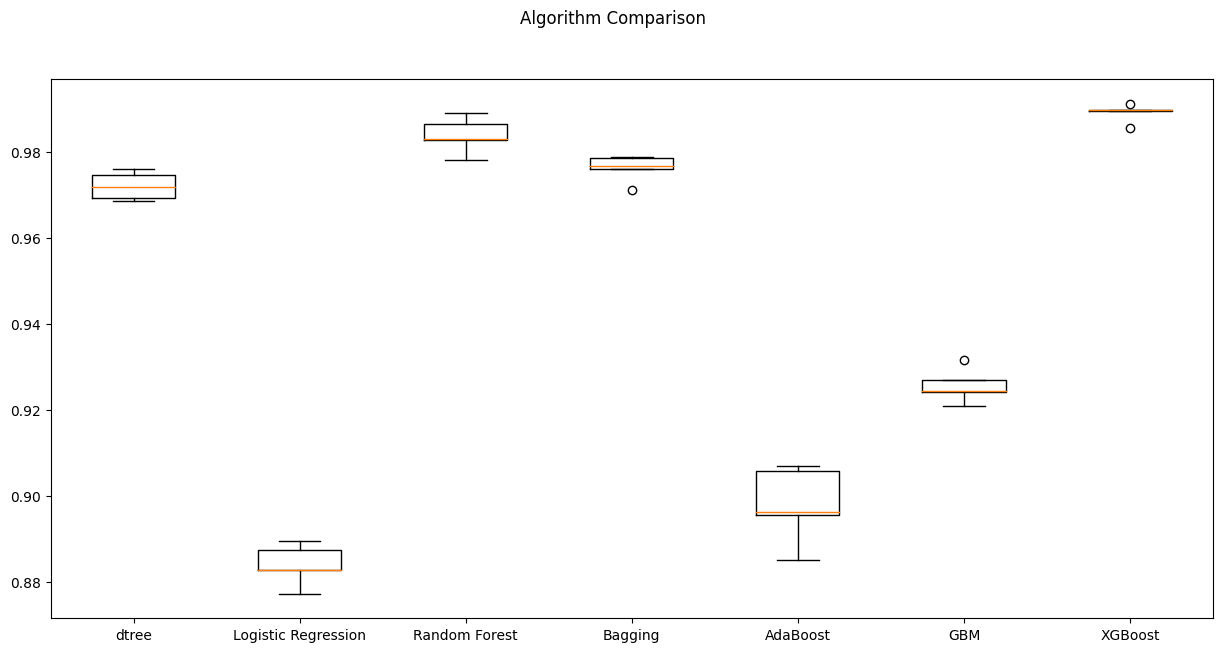

In [43]:
#Visualize CV scores on oversampled data of all models defined above using a boxplot
fig = plt.figure(figsize= (15,7))

fig.suptitle('Algorithm Comparison')
ax= fig.add_subplot(111)

plt.boxplot(results1)
ax.set_xticklabels(names)

plt.show()

- With models built on oversampled data:
  - When taking generalization into account by comparing training and validation set performance with respect to cross-validation recall score, the models performing the best are GBM, Adaboost and Logistic Regression


### Model Building with Undersampled data

In [44]:
# Random undersampler for under sampling the data
rus = RandomUnderSampler(random_state=1, sampling_strategy=1)
X_train_un, y_train_un = rus.fit_resample(X_train, y_train)

In [45]:
print("Before Undersampling, counts of label '1': {}".format(sum(y_train==1)))
print("Before Undersampling, counts of label '0': {} \n".format(sum(y_train==0)))

print("After Undersampling, counts of label '1': {}".format(sum(y_train_un==1)))
print("After Undersampling, counts of label '0': {} \n".format(sum(y_train_un==0)))

print("After Undersampling, the shape of X_train: {}".format(X_train_un.shape))
print("After Undersampling, the shape of y_train: {} \n".format(y_train_un.shape))

Before Undersampling, counts of label '1': 832
Before Undersampling, counts of label '0': 14168 

After Undersampling, counts of label '1': 832
After Undersampling, counts of label '0': 832 

After Undersampling, the shape of X_train: (1664, 40)
After Undersampling, the shape of y_train: (1664,) 



In [46]:
%%time

models = []  # Empty list to store all the models

# Appending models into the list
models.append(("dtree", DecisionTreeClassifier(random_state=1)))
models.append(("Logistic Regression", LogisticRegression(random_state=1)))
models.append(("Random Forest", RandomForestClassifier(random_state=1)))
models.append(("Bagging", BaggingClassifier(random_state=1)))
models.append(("AdaBoost", AdaBoostClassifier(random_state=1)))
models.append(("GBM", GradientBoostingClassifier(random_state=1)))
models.append(("XGBoost", XGBClassifier(random_state=1,eval_metric='logloss')))


results1 = []  # Empty list to store all model's CV scores
names = []  # Empty list to store name of the models


# loop through all models to get the mean cross validated score
print("\n" "Cross-Validation performance on training dataset:" "\n")

for name, model in models:
    kfold = StratifiedKFold(
        n_splits=5, shuffle=True, random_state=1
    )  # Setting number of splits equal to 5
    cv_result = cross_val_score(
        estimator=model, X=X_train_un, y=y_train_un, scoring=scorer, cv=kfold
    )
    results1.append(cv_result)
    names.append(name)
    print("{}: {}".format(name, cv_result.mean()))

print("\n" "Validation Performance:" "\n")

for name, model in models:
    model.fit(X_train_un, y_train_un)
    scores = recall_score(y_val, model.predict(X_val))
    print("{}: {}".format(name, scores))


Cross-Validation performance on training dataset:

dtree: 0.8617776495202367
Logistic Regression: 0.8726138085275232
Random Forest: 0.9038669648654498
Bagging: 0.8641945025611427
AdaBoost: 0.8666113556020489
GBM: 0.8990621167303946
XGBoost: 0.9014717552846114

Validation Performance:

dtree: 0.841726618705036
Logistic Regression: 0.8525179856115108
Random Forest: 0.8920863309352518
Bagging: 0.8705035971223022
AdaBoost: 0.8489208633093526
GBM: 0.8884892086330936
XGBoost: 0.89568345323741
CPU times: user 48.6 s, sys: 506 ms, total: 49.2 s
Wall time: 56.1 s


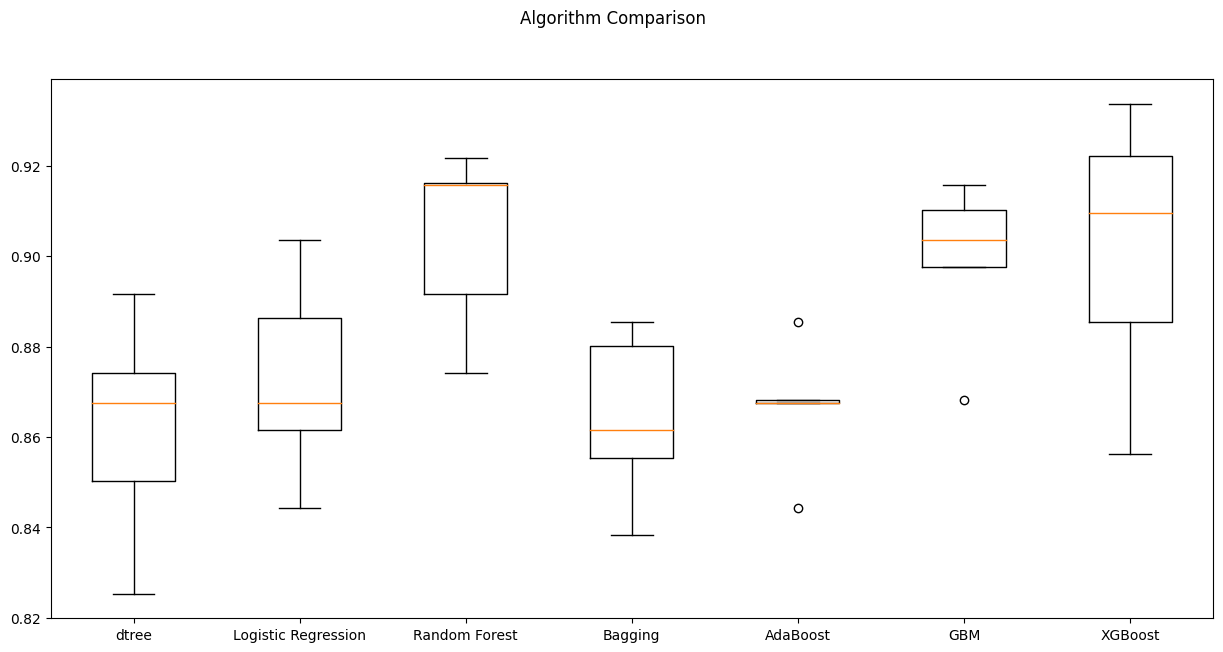

In [47]:
#Visualize CV scores on undersampled data of all models defined above using a boxplot
fig = plt.figure(figsize= (15,7))

fig.suptitle('Algorithm Comparison')
ax= fig.add_subplot(111)

plt.boxplot(results1)
ax.set_xticklabels(names)

plt.show()

- With models built on undersampled data:
  - When taking generalization into account by comparing training and validation set performance with respect to cross-validation recall score, the models performing the best are Random Forest, XGBoost, GBM and Bagging.

**Model Selection For Hyperparemeter Tuning**


- Looking at all the models and how they perform in respect to recall along with generalizing the performance on the validation set, we can some models to tune using hyperparemeters.

  - The models built on the original data generally are not performing as well with respect to recall scores of models built on oversampling and undersampling the data.

  - The models with the best performance and generalization when applied to the validation data set are
    - AdaBoost with oversampling
    - GBM with oversampling
    - Random Forest with undersampling
    - XGBoost with undersampling

**We will attempt to improve the performance of these models using Hyperparameter tuning**

## HyperparameterTuning

### Tuning AdaBoost with Oversampled Data

In [67]:
%%time

#defining model
model= AdaBoostClassifier(random_state=1)

#Parameter Grid to pass in RandomizedSearchCV
param_grid = {
    "n_estimators": [100, 150, 200],
    "learning_rate": [0.2, 0.05],
    "base_estimator": [
        DecisionTreeClassifier(max_depth=1, random_state=1),
        DecisionTreeClassifier(max_depth=2, random_state=1),
        DecisionTreeClassifier(max_depth=3, random_state=1),
        ]
    }

#type of scoring used to compare paremeter combinations
scorer= metrics.make_scorer(metrics.recall_score)

#calling RandomizedSearchCV
randomized_cv= RandomizedSearchCV(estimator= model, param_distributions=param_grid, scoring=scorer, cv=5, n_jobs=-1, random_state=1, n_iter=30)

#Fitting parameters in RandomizedSearchCV
randomized_cv.fit(X_train_over, y_train_over)

print(
    'Best Parameters:{} \nScore: {}'.format(randomized_cv.best_params_, randomized_cv.best_score_)
)


Best Parameters:{'n_estimators': 200, 'learning_rate': 0.2, 'base_estimator': DecisionTreeClassifier(max_depth=3, random_state=1)} 
Score: 0.9714853746337214
CPU times: user 3min 6s, sys: 10.3 s, total: 3min 17s
Wall time: 1h 15min 24s


In [48]:
#building model with best parameters
ada_tuned = AdaBoostClassifier(
    n_estimators= 200 , learning_rate= 0.2, base_estimator= DecisionTreeClassifier(max_depth=3 , random_state=1)
)

#Fit the model on oversampled data
ada_tuned.fit(X_train_over, y_train_over)

AdaBoostClassifier(base_estimator=DecisionTreeClassifier(max_depth=3,
                                                         random_state=1),
                   learning_rate=0.2, n_estimators=200)

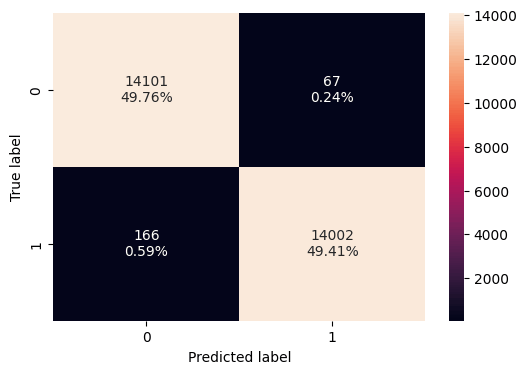

In [49]:
#Create a confusion matrix for ada_tuned on train data set
confusion_matrix_sklearn(ada_tuned, X_train_over, y_train_over)

In [50]:
#check the performance on the train data set
ada_tuned_train_perf = model_performance_classification_sklearn(ada_tuned, X_train_over, y_train_over)
ada_tuned_train_perf

,Accuracy,Recall,Precision,F1
0,0.992,0.988,0.995,0.992


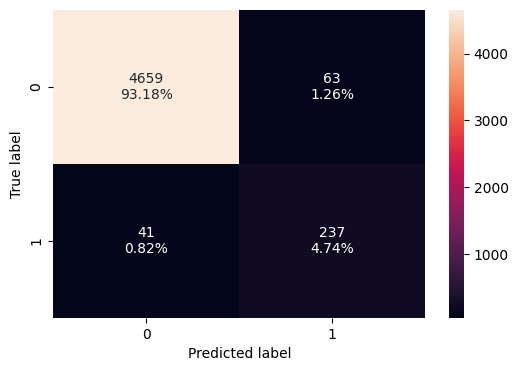

In [51]:
#Create a confusion matrix for ada_tuned on validation data set
confusion_matrix_sklearn(ada_tuned, X_val, y_val)

In [52]:
#check the performance on the validation data set
ada_tuned_val_perf = model_performance_classification_sklearn(ada_tuned, X_val, y_val)
ada_tuned_val_perf

,Accuracy,Recall,Precision,F1
0,0.979,0.853,0.790,0.820


- The Tuned AdaBoost model with oversampled data has a recall score of 0.988 on the train data set and a recall score of 0.853 on the validation data set.
- This model is not generalizing well due to the difference in performance of recall between the train and validation data sets.

### Tuning Gradient Boosting (GBM) with Oversampled Data

In [ ]:
%%time

#defining model
model= GradientBoostingClassifier(random_state=1)

#Parameter Grid to pass in RandomizedSearchCV
param_grid = {
     "n_estimators": np.arange(100,150,25),
     "learning_rate": [0.2, 0.05, 1],
     "subsample":[0.5,0.7],
     "max_features":[0.5,0.7]
     }

#type of scoring used to compare paremeter combinations
scorer= metrics.make_scorer(metrics.recall_score)

#calling RandomizedSearchCV
randomized_cv= RandomizedSearchCV(estimator= model, param_distributions=param_grid, scoring=scorer, cv=5, n_jobs=-1, random_state=1, n_iter=30)

#Fitting parameters in RandomizedSearchCV
randomized_cv.fit(X_train_over, y_train_over)

print(
    'Best Parameters:{} \nScore: {}'.format(randomized_cv.best_params_, randomized_cv.best_score_)
)


Best Parameters:{'subsample': 0.7, 'n_estimators': 125, 'max_features': 0.5, 'learning_rate': 1} 
Score: 0.9723322092856124
CPU times: user 26.7 s, sys: 3.58 s, total: 30.3 s
Wall time: 17min 46s


In [53]:
#building model with best parameters
gbm_tuned = GradientBoostingClassifier(
    n_estimators= 125, learning_rate= 1, subsample = 0.7, max_features=0.5, random_state=1
)

#Fit the model on oversampled data
gbm_tuned.fit(X_train_over, y_train_over)

GradientBoostingClassifier(learning_rate=1, max_features=0.5, n_estimators=125,
                           random_state=1, subsample=0.7)

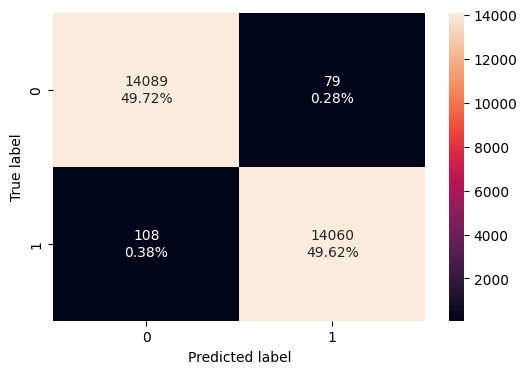

In [54]:
#Create a confusion matrix for gbm_tuned on train data set
confusion_matrix_sklearn(gbm_tuned, X_train_over, y_train_over)

In [55]:
#check the performance on the train data set
gbm_tuned_train_perf = model_performance_classification_sklearn(gbm_tuned, X_train_over, y_train_over)
gbm_tuned_train_perf

,Accuracy,Recall,Precision,F1
0,0.993,0.992,0.994,0.993


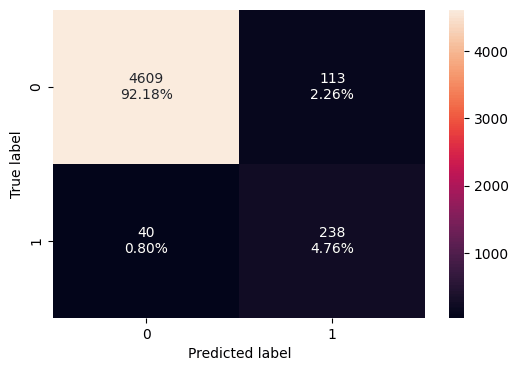

In [56]:
#Create a confusion matrix for gbm_tuned on validation data set
confusion_matrix_sklearn(gbm_tuned, X_val, y_val)

In [57]:
#check the performance on the validation data set
gbm_tuned_val_perf = model_performance_classification_sklearn(gbm_tuned, X_val, y_val)
gbm_tuned_val_perf

,Accuracy,Recall,Precision,F1
0,0.969,0.856,0.678,0.757


- The Gradient Boost (GBM) model with oversampled data has a recall score of 0.992 on the train data set and a recall score of 0.856 on the validation data set.
- This model is not generalizing well due to the difference in performance of recall between the train and validation data sets.

### Tuning Random Forest with Undersampled Data

In [ ]:
%%time

#defining model
model= RandomForestClassifier(random_state=1)

#Parameter Grid to pass in RandomizedSearchCV
param_grid = {
     "n_estimators": [200,250,300],
     "min_samples_leaf": np.arange(1, 4),
     "max_features": [np.arange(0.3, 0.6, 0.1),'sqrt'],
     "max_samples": np.arange(0.4, 0.7, 0.1)
      }

#type of scoring used to compare paremeter combinations
scorer= metrics.make_scorer(metrics.recall_score)

#calling RandomizedSearchCV
randomized_cv= RandomizedSearchCV(estimator= model, param_distributions=param_grid, scoring=scorer, cv=5, n_jobs=-1, random_state=1, n_iter=30)

#Fitting parameters in RandomizedSearchCV
randomized_cv.fit(X_train_un, y_train_un)

print(
    'Best Parameters:{} \nScore: {}'.format(randomized_cv.best_params_, randomized_cv.best_score_)
)

Best Parameters:{'n_estimators': 300, 'min_samples_leaf': 2, 'max_samples': 0.5, 'max_features': 'sqrt'} 
Score: 0.8990116153235697
CPU times: user 2.19 s, sys: 114 ms, total: 2.3 s
Wall time: 55.2 s


In [58]:
#building model with best parameters
rf_tuned = RandomForestClassifier(
    n_estimators = 300 , min_samples_leaf = 2 , max_features = 'sqrt' , max_samples = 0.5, random_state=1
)

#Fit the model on the undersampled data
rf_tuned.fit(X_train_un, y_train_un)

RandomForestClassifier(max_samples=0.5, min_samples_leaf=2, n_estimators=300,
                       random_state=1)

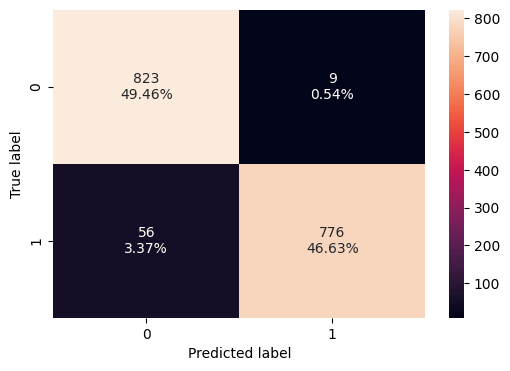

In [59]:
#Create a confusion matrix for rf_tuned on train data set
confusion_matrix_sklearn(rf_tuned, X_train_un, y_train_un)

In [60]:
#check the performance on the train data set
rf_tuned_train_perf = model_performance_classification_sklearn(rf_tuned, X_train_un, y_train_un)
rf_tuned_train_perf

,Accuracy,Recall,Precision,F1
0,0.961,0.933,0.989,0.960


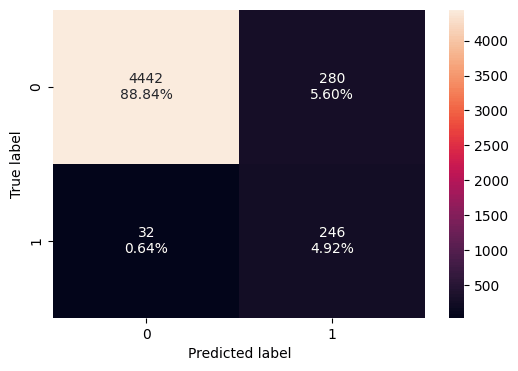

In [61]:
#Create a confusion matrix for rf_tuned on validation data set
confusion_matrix_sklearn(rf_tuned, X_val, y_val)

In [62]:
#check the performance on the validation data set
rf_tuned_val_perf = model_performance_classification_sklearn(rf_tuned, X_val, y_val)
rf_tuned_val_perf

,Accuracy,Recall,Precision,F1
0,0.938,0.885,0.468,0.612


- The Random Forest model with undersampled data has a recall score of 0.933 on the train data set and a recall score of 0.885 on the validation data set.
- This model is generalizing better than the prior models but is still not generalizing very well due to the difference in performance of recall between the train and validation data sets.

### Tuning XGBoost with Undersampled Data

In [ ]:
%%time

#defining model
model= XGBClassifier(random_state=1, eval_metric='logloss')

#Parameter Grid to pass in RandomizedSearchCV
param_grid={
    'n_estimators': [150, 200, 250],
    'scale_pos_weight': [5,10],
    'learning_rate': [0.1,0.2],
    'gamma': [0,3,5],
    'subsample': [0.8,0.9]
    }

#type of scoring used to compare paremeter combinations
scorer= metrics.make_scorer(metrics.recall_score)

#calling RandomizedSearchCV
randomized_cv= RandomizedSearchCV(estimator= model, param_distributions=param_grid, scoring=scorer, cv=5, n_jobs=-1, random_state=1, n_iter=30)

#Fitting parameters in RandomizedSearchCV
randomized_cv.fit(X_train_un, y_train_un)

print(
    'Best Parameters:{} \nScore: {}'.format(randomized_cv.best_params_, randomized_cv.best_score_)
)

Best Parameters:{'subsample': 0.9, 'scale_pos_weight': 10, 'n_estimators': 200, 'learning_rate': 0.1, 'gamma': 5} 
Score: 0.9290599523843879
CPU times: user 1.51 s, sys: 126 ms, total: 1.63 s
Wall time: 48.7 s


In [63]:
#building model with best parameters
xgb_tuned = XGBClassifier(
    subsample= 0.9, scale_pos_weight= 10, n_estimators= 200, learning_rate= 0.1, gamma= 5, random_state=1, eval_metric='logloss'
)

#Fit the model on the undersampled data
xgb_tuned.fit(X_train_un, y_train_un)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, gamma=5, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.1, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=200,
              n_jobs=None, num_parallel_tree=None, random_state=1, ...)

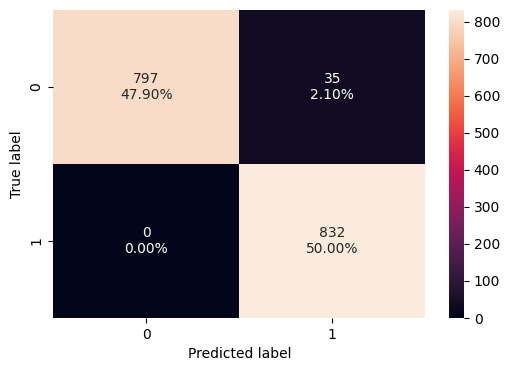

In [64]:
#Create a confusion matrix for xgb_tuned on train data set
confusion_matrix_sklearn(xgb_tuned, X_train_un, y_train_un)

In [65]:
#check the performance on the train data set
xgb_tuned_train_perf = model_performance_classification_sklearn(xgb_tuned, X_train_un, y_train_un)
xgb_tuned_train_perf

,Accuracy,Recall,Precision,F1
0,0.979,1.000,0.960,0.979


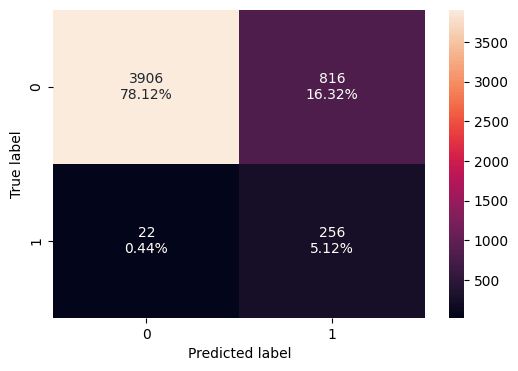

In [66]:
#Create a confusion matrix for xgb_tuned on validation data set
confusion_matrix_sklearn(xgb_tuned, X_val, y_val)

In [67]:
#check the performance on the validation data set
xgb_tuned_val_perf = model_performance_classification_sklearn(xgb_tuned, X_val, y_val)
xgb_tuned_val_perf

,Accuracy,Recall,Precision,F1
0,0.832,0.921,0.239,0.379


- The tuned XGBoost model with undersampled data has a perfect recall score of 1.0 on the train data set and a recall score of 0.921 on the validation data set.
- This model is performing the best in regards to recall, however it is not generalizing very well due to the difference between recall performance in the train and validation data sets.

## Model performance comparison and choosing the final model

In [68]:
#model performance comparison on train data set

models_train_comp_df = pd.concat(
    [ada_tuned_train_perf.T,
     gbm_tuned_train_perf.T,
     rf_tuned_train_perf.T,
     xgb_tuned_train_perf.T,
     ], axis=1
)
models_train_comp_df.columns=[
    'AdaBoost Classifier Tuned with oversampled data',
    'Gradient Boost Classifier Tuned with oversampled data',
    'Random Forest Classifier Tuned with undersampled data',
    'XGBoost Classifier Tuned with undersampled data',
]

print('Training Performance Comparison:')
models_train_comp_df

Training Performance Comparison:


,AdaBoost Classifier Tuned with oversampled data,Gradient Boost Classifier Tuned with oversampled data,Random Forest Classifier Tuned with undersampled data,XGBoost Classifier Tuned with undersampled data
Accuracy,0.992,0.993,0.961,0.979
Recall,0.988,0.992,0.933,1.000
Precision,0.995,0.994,0.989,0.960
F1,0.992,0.993,0.960,0.979


In [69]:
#model performance comparison on validation data set
models_val_comp_df = pd.concat(
    [ada_tuned_val_perf.T,
     gbm_tuned_val_perf.T,
     rf_tuned_val_perf.T,
     xgb_tuned_val_perf.T,
     ], axis=1
)
models_val_comp_df.columns=[
    'AdaBoost Classifier Tuned with oversampled data',
    'Gradient Boost Classifier Tuned with oversampled data',
    'Random Forest Classifier Tuned with undersampled data',
    'XGBoost Classifier Tuned with undersampled data',
]

print('Validation Performance Comparison:')
models_val_comp_df

Validation Performance Comparison:


,AdaBoost Classifier Tuned with oversampled data,Gradient Boost Classifier Tuned with oversampled data,Random Forest Classifier Tuned with undersampled data,XGBoost Classifier Tuned with undersampled data
Accuracy,0.979,0.969,0.938,0.832
Recall,0.853,0.856,0.885,0.921
Precision,0.790,0.678,0.468,0.239
F1,0.820,0.757,0.612,0.379


- rf_tuned is the best model out of the tuned models since it is generalizing the best in respect to the recall with the difference in recall between train and validation data sets being the least among the 4 models.
  - The recall score for rf-tuned on the train data set is 0.0933
  - The recall score for rf-tuned on the validation data set is 0.885

In [70]:
#Set the final model variable
final_model_rf_tuned = rf_tuned

### Test set final performance

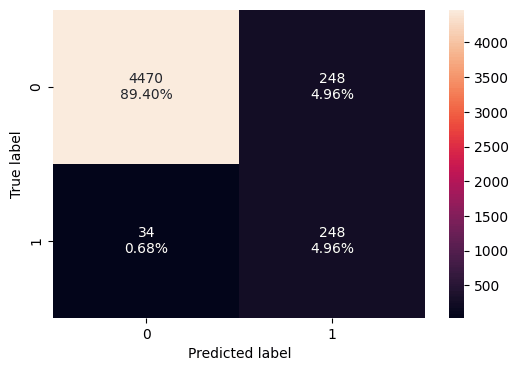

In [71]:
#Create a confusion matrix for final_model_rf_tuned on the test data set
confusion_matrix_sklearn(final_model_rf_tuned, X_test, y_test)

In [72]:
#check the performance on the validation data set
final_model_test_perf = model_performance_classification_sklearn(final_model_rf_tuned, X_test, y_test)
final_model_test_perf

,Accuracy,Recall,Precision,F1
0,0.944,0.879,0.500,0.638


- The recall score of rf_tuned on the test data set is 0.879 which is comparable to the performance of the model on the validation data set (0.885)
- The performance on the test data set is generalized


**We will now take a look at the feature importances of the final model**

####Feature Importances

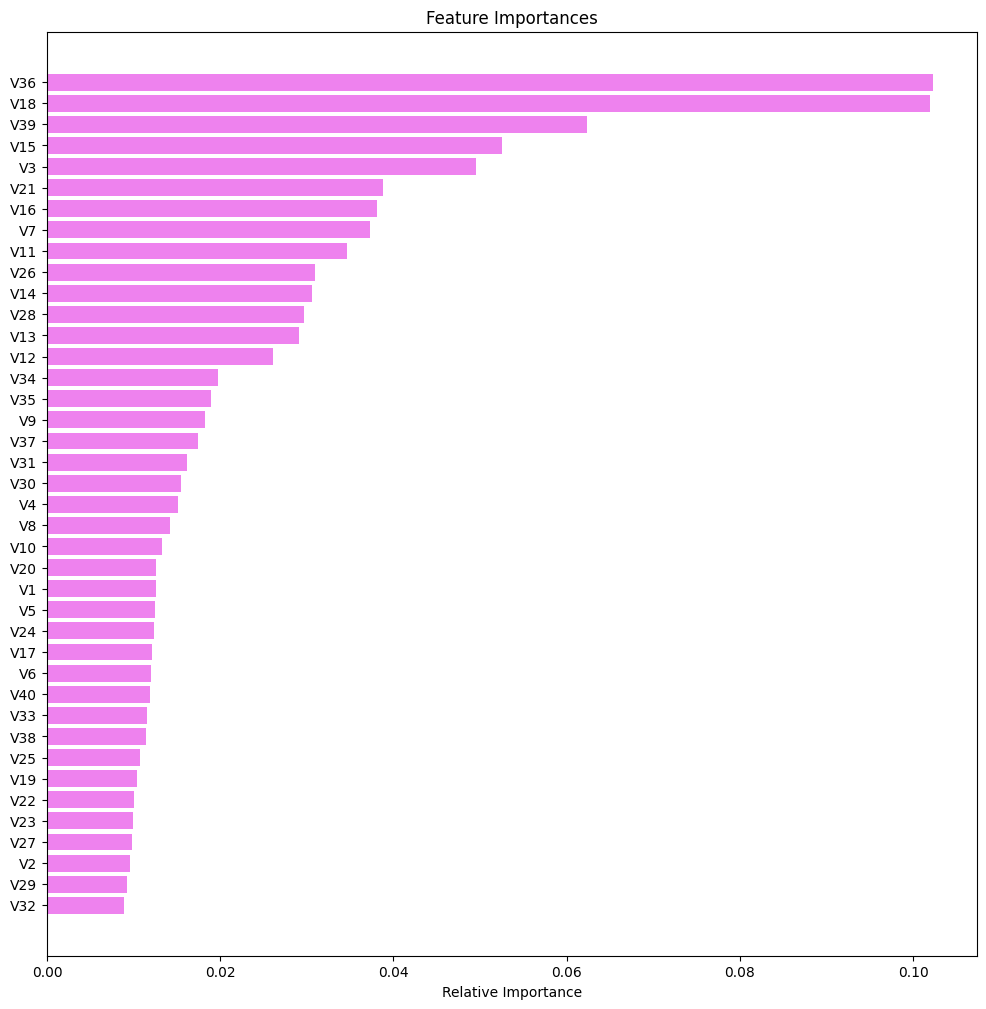

In [73]:
feature_names= X.columns
importances = final_model_rf_tuned.feature_importances_
indices = np.argsort(importances)

plt.figure(figsize=(12,12))
plt.title('Feature Importances')
plt.barh(range(len(indices)), importances[indices], color='violet', align='center')
plt.yticks(range(len(indices)), [feature_names[i] for i in indices])
plt.xlabel('Relative Importance')
plt.show()

- The most important feature is V36, followed closely by V18, with V39 being the next variable of high importance within the final model.

## Pipelines to Build the Final Model


In [74]:
#separating the target variable and the other variables
X1= df.drop(columns= 'Target')
Y1= df['Target']

#Test data set is already separated so we can go ahead an separate the target variable from the other variables in the test data set
X_test1 = df_test.drop(columns='Target')
Y_test1 = df_test['Target']

In [75]:
#create a pipeline for the final model
pipe_model = Pipeline(steps= [
    ('imputer', SimpleImputer(strategy='median')),
    (
        'clf',
        RandomForestClassifier(
            n_estimators = 300 ,
            min_samples_leaf = 2 ,
            max_features = 'sqrt' ,
            max_samples = 0.5,
            random_state=1
            )
        ) ])

In [76]:
#missing value treatment on X1
imputer= SimpleImputer(strategy='median')
X1= imputer.fit_transform(X1)

In [77]:
# Random undersampler for under sampling the data
rus = RandomUnderSampler(random_state=1, sampling_strategy=1)
X1_train_un, Y1_train_un = rus.fit_resample(X1, Y1)

In [78]:
#Fit the model on the undersampled data
pipe_model.fit(X1_train_un, Y1_train_un)

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('clf',
                 RandomForestClassifier(max_samples=0.5, min_samples_leaf=2,
                                        n_estimators=300, random_state=1))])

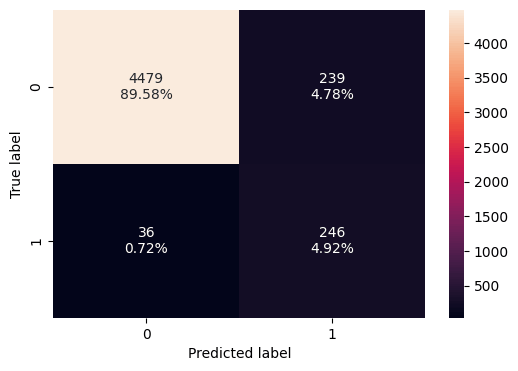

In [79]:
#Create a confusion matrix for pipe_model on the test data set
confusion_matrix_sklearn(pipe_model, X_test1, Y_test1)

In [80]:
#Check the performance on the test set
pipe_model_test = model_performance_classification_sklearn(pipe_model, X_test1, Y_test1 )
pipe_model_test

,Accuracy,Recall,Precision,F1
0,0.945,0.872,0.507,0.641


- The model is performing well within the pipeline evidenced by comparable recall scores on the test data set prior to building the pipeline, 0.879, and runnning the test data through the pipeline, 0.872.
  - The slight variation in the recall scores is due to the final model within the pipeline being fit on the entire training data set (20,000 rows), while the final model resulting from hypertuning was fit on 75% (15,000 rows). The remaining 25% (5,000) rows was used for validation.

# Business Insights and Conclusions

**Final Model**
  - The final model selected is the Random Forest Classifier using Random Undersampling to account for bias resulting from an imbalance in the Target Variable; predicting generator failure of wind turbines.
    - 94.5% of the target variable categorized as 'No Failure' (0)
    - 5.5% of the target variable vategorized as 'Failure' (1)

  - The model was tuned to improve the performance of our target metric, Recall, which aims to reduce the occurence of False Negatives.
    - False Negatives: Real failures which are not predicted by the model
    - Precision is not as important, because a False Positive, predicting failure in a generator when there is no failure is much cheaper.
  
  - The Random Forest Classifier's recall performance was further improved through Hyperparameter tuning utilizing Randomized Search Classification.

  - The final model: Tuned Random Forest Classifier fit on undersampled data was then applied to a pipeline and yielded the following results on the Test Data set.
    - Recall (Target Performance Metric): 87.2%
    - Accuracy: 94.5%
    - Precision: 50.7%
    - F1: 64.1%
  * Even through precision is low, the model is still performing well because the cost of a False Positive is less than the cost of a False Negative.

  - The test data set containing 5000 rows had an instance of 36 False Negatives (0.78%) where the model failed to predict a real failure.


 **Feature Importances**

  - The final model ranked the following indepenedent variables as the most important features in the model failure.
    1. V36
    2. V18
    3. V39
    4. V15
    5. V3
  - The final model ranked the following indepenedent variables as the least important features in the model contributing to failure.
    36. V23
    37. V27
    38. V2
    39. V29
    40. V32

**Additional Comments**
  * Without context behind the independent variables it is difficult to make recommendations.
    - If the variables of high importance are able to be controlled such as temperature and humidity around where the generator is located. These can be adjusted and maintained to prevent prevent failure.
    - If the variables of high importance are only measurable, these can be flagged when reaching certain thresholds, especially when these values are correlated with failure and the model is predicting no failure.
      - This can be used as an extra level of protection against failure to address the small instance of False Negatives produced by the model.
    
  

***